In [1]:
from pathlib import Path
import pandas as pd

def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"

In [2]:
# Load the datasets
volume_25 = pd.read_parquet(DATASETS_DIR / "9ed666cb7603b0b1/volume.parquet")
volume_50 = pd.read_parquet(DATASETS_DIR / "f42c8eca7e1d67cf/volume.parquet")
volume_100 = pd.read_parquet(DATASETS_DIR / "486b5b7c40ebe4fd/volume.parquet")

dollar_25 = pd.read_parquet(DATASETS_DIR / "148ef03cfd675fa4/notional.parquet")
dollar_50 = pd.read_parquet(DATASETS_DIR / "7e8a02ceb035e8f9/notional.parquet")
dollar_100 = pd.read_parquet(DATASETS_DIR / "5e4cc12bf931053c/notional.parquet")

In [23]:
print(volume_25.head())

                                                                      bar_id  \
datetime                                                                       
2021-09-01 00:05:49.466000+00:00  binance_spot_ETHUSDT_volume_fb81d1c27c8c:0   
2021-09-01 00:14:18.792000+00:00  binance_spot_ETHUSDT_volume_fb81d1c27c8c:1   
2021-09-01 00:26:01.271000+00:00  binance_spot_ETHUSDT_volume_fb81d1c27c8c:2   
2021-09-01 00:45:44.390000+00:00  binance_spot_ETHUSDT_volume_fb81d1c27c8c:3   
2021-09-01 00:54:54.160000+00:00  binance_spot_ETHUSDT_volume_fb81d1c27c8c:4   

                                                                 series_id  \
datetime                                                                     
2021-09-01 00:05:49.466000+00:00  binance_spot_ETHUSDT_volume_fb81d1c27c8c   
2021-09-01 00:14:18.792000+00:00  binance_spot_ETHUSDT_volume_fb81d1c27c8c   
2021-09-01 00:26:01.271000+00:00  binance_spot_ETHUSDT_volume_fb81d1c27c8c   
2021-09-01 00:45:44.390000+00:00  binance_spot_ET

In [3]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

volume_25, volume_50, volume_100, dollar_25, dollar_50, dollar_100 = map(
    set_datetime_index,
    (volume_25, volume_50, volume_100, dollar_25, dollar_50, dollar_100)
)

## Bollinger bands: width 5%. Counted how many time prices cross the bands out (from within the bands outside the bands)

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

datasets = {
    "Volume 25": volume_25,
    "Volume 50": volume_50,
    "Volume 100": volume_100,
    "Dollar 25": dollar_25,
    "Dollar 50": dollar_50,
    "Dollar 100": dollar_100,
}

MA_WINDOW = "7D"
BAND_WIDTH = 0.05
MIN_BARS = 20

colors = {
    25: "tab:blue",
    50: "tab:orange",
    100: "tab:green"
}


def compute_band_crossings(df):
    data = df[
        ["close", "segment_id", "bar_seq"]
    ].sort_values(
        ["segment_id", "bar_seq"],
        kind="stable"
    ).copy()

    data["close"] = pd.to_numeric(data["close"], errors="coerce")
    data.loc[data["close"] <= 0, "close"] = np.nan

    segments = []

    for _, segment in data.groupby("segment_id", sort=False):
        segment = segment.sort_index(kind="stable").copy()

        # Rolling MA: preceding 7 calendar days only.
        # The current bar and bars with the same timestamp are excluded.
        segment["ma"] = segment["close"].rolling(
            MA_WINDOW,
            min_periods=MIN_BARS,
            closed="left"
        ).mean()

        segment["upper"] = segment["ma"] * (1 + BAND_WIDTH)
        segment["lower"] = segment["ma"] * (1 - BAND_WIDTH)

        valid = segment["close"].notna() & segment["ma"].notna()

        inside = (
            valid
            & segment["close"].between(
                segment["lower"],
                segment["upper"]
            )
        )

        previous_inside = inside.shift(1, fill_value=False)
        previous_valid = valid.shift(1, fill_value=False)

        segment["eligible"] = valid & previous_valid

        # Inside -> above upper band
        segment["cross_upper"] = (
            previous_inside
            & (segment["close"] > segment["upper"])
        )

        # Inside -> below lower band
        segment["cross_lower"] = (
            previous_inside
            & (segment["close"] < segment["lower"])
        )

        segments.append(segment)

    return pd.concat(segments).sort_index(kind="stable")


# Compute crossings for all datasets
band_results = {
    name: compute_band_crossings(df)
    for name, df in datasets.items()
}


# Monthly counts and normalized crossing rates
monthly_crossings = {}
monthly_rates = {}
summary_rows = []

for name, df in band_results.items():

    monthly = df[
        ["cross_upper", "cross_lower"]
    ].resample("MS").sum()

    monthly_crossings[name] = monthly

    eligible_monthly = df["eligible"].resample("MS").sum()

    monthly_rates[name] = (
        1000 * monthly.sum(axis=1)
        / eligible_monthly.replace(0, np.nan)
    )

    upper_count = int(df["cross_upper"].sum())
    lower_count = int(df["cross_lower"].sum())
    total = upper_count + lower_count
    eligible = int(df["eligible"].sum())

    summary_rows.append({
        "Dataset": name,
        "Upper Crossings": upper_count,
        "Lower Crossings": lower_count,
        "Total Crossings": total,
        "Crossings / 1000 Bars": 1000 * total / eligible
        if eligible else np.nan,
        "Crossings / Month": total / (eligible_monthly.gt(0).sum())
        if eligible_monthly.gt(0).any() else np.nan
    })

summary = pd.DataFrame(summary_rows).set_index("Dataset")

print("Bollinger-Style Band Crossings (±5%)")
print(summary.round(3).to_string())

Bollinger-Style Band Crossings (±5%)
            Upper Crossings  Lower Crossings  Total Crossings  Crossings / 1000 Bars  Crossings / Month
Dataset                                                                                                
Volume 25               928              930             1858                 12.451             30.967
Volume 50              1317             1295             2612                  8.760             43.533
Volume 100             1827             1847             3674                  6.172             61.233
Dollar 25               991              899             1890                 12.845             31.500
Dollar 50              1408             1304             2712                  9.224             45.200
Dollar 100             1998             1812             3810                  6.405             63.500


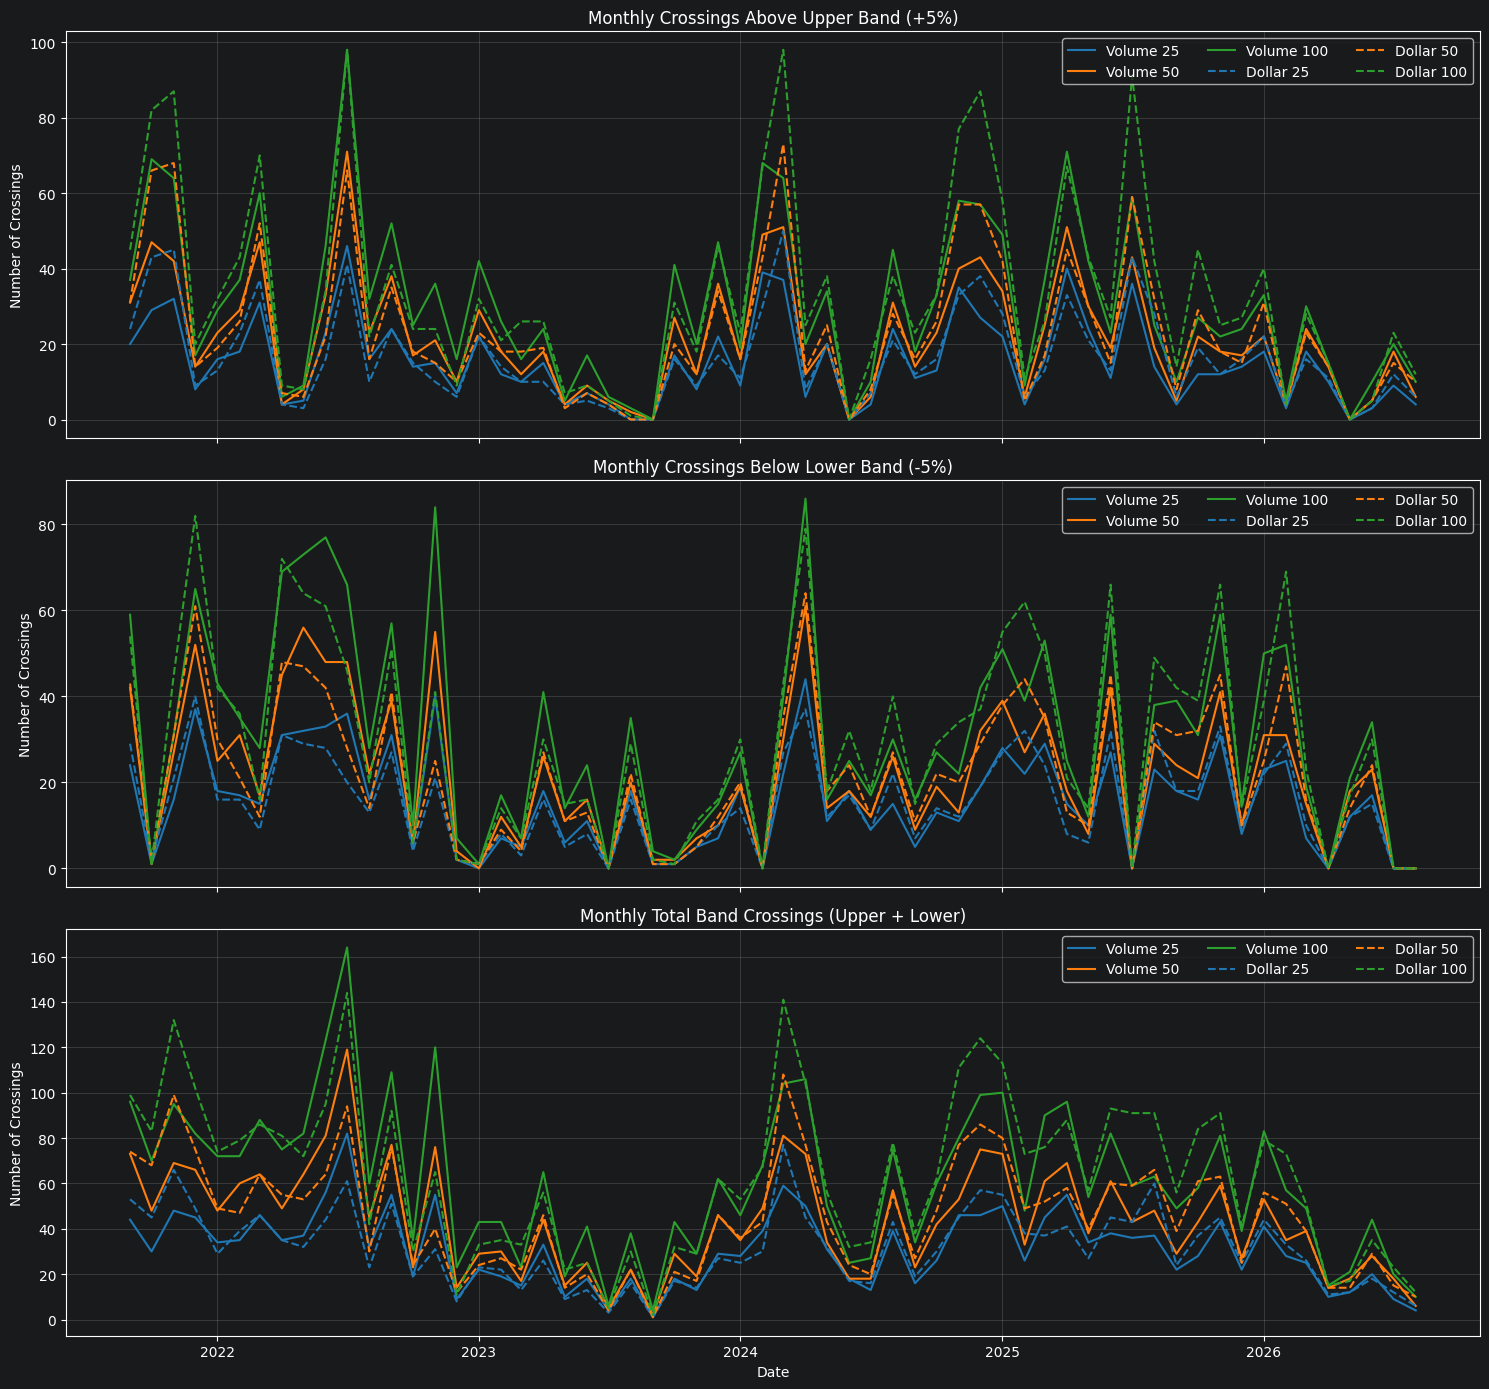

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(15, 14), sharex=True)

for name in datasets:
    target = int(name.split()[-1])
    linestyle = "-" if name.startswith("Volume") else "--"

    monthly = monthly_crossings[name]

    axes[0].plot(
        monthly.index,
        monthly["cross_upper"],
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.5,
        label=name
    )

    axes[1].plot(
        monthly.index,
        monthly["cross_lower"],
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.5,
        label=name
    )

    axes[2].plot(
        monthly.index,
        monthly["cross_upper"] + monthly["cross_lower"],
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.5,
        label=name
    )

axes[0].set_title("Monthly Crossings Above Upper Band (+5%)")
axes[1].set_title("Monthly Crossings Below Lower Band (-5%)")
axes[2].set_title("Monthly Total Band Crossings (Upper + Lower)")

for ax in axes:
    ax.set_ylabel("Number of Crossings")
    ax.legend(ncol=3)
    ax.grid(True, alpha=0.3)

axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()

## Cusum Filter where Yt are returns and h=0.05

In [6]:
H = 0.05

In [7]:
def cusum_filter(df, h=0.05):
    data = df.sort_values(
        ["segment_id", "bar_seq"],
        kind="stable"
    )

    close = pd.to_numeric(data["close"], errors="coerce")
    log_close = np.log(close.where(close > 0))

    # Log returns within continuous segments
    returns = log_close.groupby(
        data["segment_id"], sort=False
    ).diff().to_numpy()

    events = np.zeros(len(data), dtype=bool)
    directions = np.zeros(len(data), dtype=np.int8)

    s_pos, s_neg = 0.0, 0.0

    segments = data["segment_id"].to_numpy()

    for i, r in enumerate(returns):

        # Reset at segment boundaries or invalid observations
        if i == 0 or segments[i] != segments[i - 1]:
            s_pos, s_neg = 0.0, 0.0

        if not np.isfinite(r):
            s_pos, s_neg = 0.0, 0.0
            continue

        s_pos = max(0.0, s_pos + r)
        s_neg = min(0.0, s_neg + r)

        if s_neg < -h:
            s_neg = 0.0
            events[i] = True
            directions[i] = -1

        elif s_pos > h:
            s_pos = 0.0
            events[i] = True
            directions[i] = 1

    event_log = pd.DataFrame({
        "close": close.to_numpy(),
        "event": events,
        "direction": directions,
        "valid_return": np.isfinite(returns)
    }, index=data.index)

    sampled_bars = data.iloc[np.flatnonzero(events)].copy()

    return sampled_bars, event_log.sort_index(kind="stable")


cusum_samples = {}
cusum_logs = {}
summary = []

for name, df in datasets.items():

    samples, log = cusum_filter(df, H)

    cusum_samples[name] = samples
    cusum_logs[name] = log

    summary.append({
        "Dataset": name,
        "Original Bars": len(df),
        "CUSUM Samples": len(samples),
        "Positive Events": int((log["direction"] == 1).sum()),
        "Negative Events": int((log["direction"] == -1).sum()),
        "Sampled (%)": 100 * len(samples) / len(df)
    })

cusum_summary = pd.DataFrame(summary).set_index("Dataset")

print("CUSUM Filter Results (h = 0.05)\n")
print(cusum_summary.round(3).to_string())

CUSUM Filter Results (h = 0.05)

            Original Bars  CUSUM Samples  Positive Events  Negative Events  Sampled (%)
Dataset                                                                                
Volume 25          149245           1626              819              807        1.089
Volume 50          298201           1734              868              866        0.581
Volume 100         595326           1815              907              908        0.305
Dollar 25          147163           1621              818              803        1.101
Dollar 50          294042           1721              864              857        0.585
Dollar 100         594869           1812              902              910        0.305


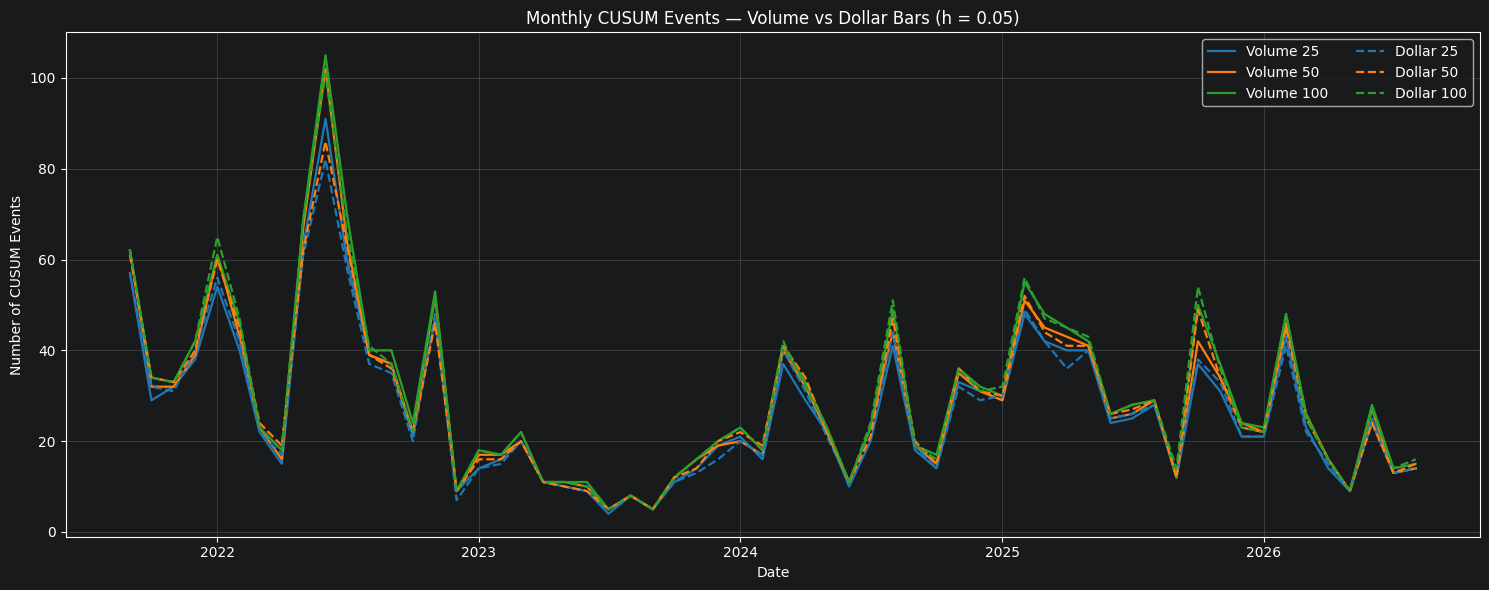

In [8]:
monthly_events = pd.DataFrame({
    name: log["event"].resample("MS").sum()
    for name, log in cusum_logs.items()
})

fig, ax = plt.subplots(figsize=(15, 6))

for name in datasets:
    target = int(name.split()[-1])
    linestyle = "-" if name.startswith("Volume") else "--"

    ax.plot(
        monthly_events.index,
        monthly_events[name],
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.6,
        label=name
    )

ax.set_title("Monthly CUSUM Events — Volume vs Dollar Bars (h = 0.05)")
ax.set_xlabel("Date")
ax.set_ylabel("Number of CUSUM Events")
ax.legend(ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
ROLLING_WINDOW = 30

def compute_rolling_volatility(sampled_df, window=30):
    data = sampled_df[
        ["close", "segment_id", "bar_seq"]
    ].sort_values(
        ["segment_id", "bar_seq"],
        kind="stable"
    ).copy()

    close = pd.to_numeric(data["close"], errors="coerce")
    log_close = np.log(close.where(close > 0))

    # Returns between consecutive sampled events
    # Never compute returns across segment boundaries
    data["event_return"] = log_close.groupby(
        data["segment_id"], sort=False
    ).diff()

    # Rolling std over sampled returns
    data["rolling_std"] = (
        data.groupby("segment_id", sort=False)["event_return"]
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).std(ddof=1)
        )
    )

    return data.sort_index(kind="stable")


rolling_results = {}
summary_rows = []

for name in datasets:

    # Bollinger: select only band-crossing events
    bb = band_results[name]
    bb_samples = bb.loc[
        bb["cross_upper"] | bb["cross_lower"]
    ]

    # CUSUM: previously selected events
    cs_samples = cusum_samples[name]

    for method, samples in [
        ("Bollinger", bb_samples),
        ("CUSUM", cs_samples)
    ]:
        result = compute_rolling_volatility(
            samples,
            ROLLING_WINDOW
        )

        rolling_results[(name, method)] = result

        rolling_std = result["rolling_std"].dropna()

        mean_std = rolling_std.mean()
        std_of_std = rolling_std.std(ddof=1)

        summary_rows.append({
            "Dataset": name,
            "Method": method,
            "Samples": len(samples),
            "Valid Windows": len(rolling_std),
            "Mean Rolling Std": mean_std,
            "Std of Rolling Std": std_of_std,
            "Variance of Rolling Std": rolling_std.var(ddof=1),
            "CV": std_of_std / mean_std
                  if mean_std > 0 else np.nan
        })


hetero_summary = pd.DataFrame(summary_rows).set_index(
    ["Dataset", "Method"]
)

print("Rolling Volatility — Bollinger vs CUSUM\n")
print(hetero_summary.round(6).to_string())

Rolling Volatility — Bollinger vs CUSUM

                      Samples  Valid Windows  Mean Rolling Std  Std of Rolling Std  Variance of Rolling Std        CV
Dataset    Method                                                                                                    
Volume 25  Bollinger     1858           1828          0.032966            0.012904                 0.000167  0.391439
           CUSUM         1626           1596          0.039338            0.002225                 0.000005  0.056558
Volume 50  Bollinger     2612           2582          0.026907            0.011389                 0.000130  0.423272
           CUSUM         1734           1704          0.038272            0.002488                 0.000006  0.064998
Volume 100 Bollinger     3674           3644          0.021940            0.011206                 0.000126  0.510750
           CUSUM         1815           1785          0.037113            0.002676                 0.000007  0.072105
Dollar 25  Boll

## Rolling standard deviation of the two-sampled series. Cusum is the least heteroscedastic

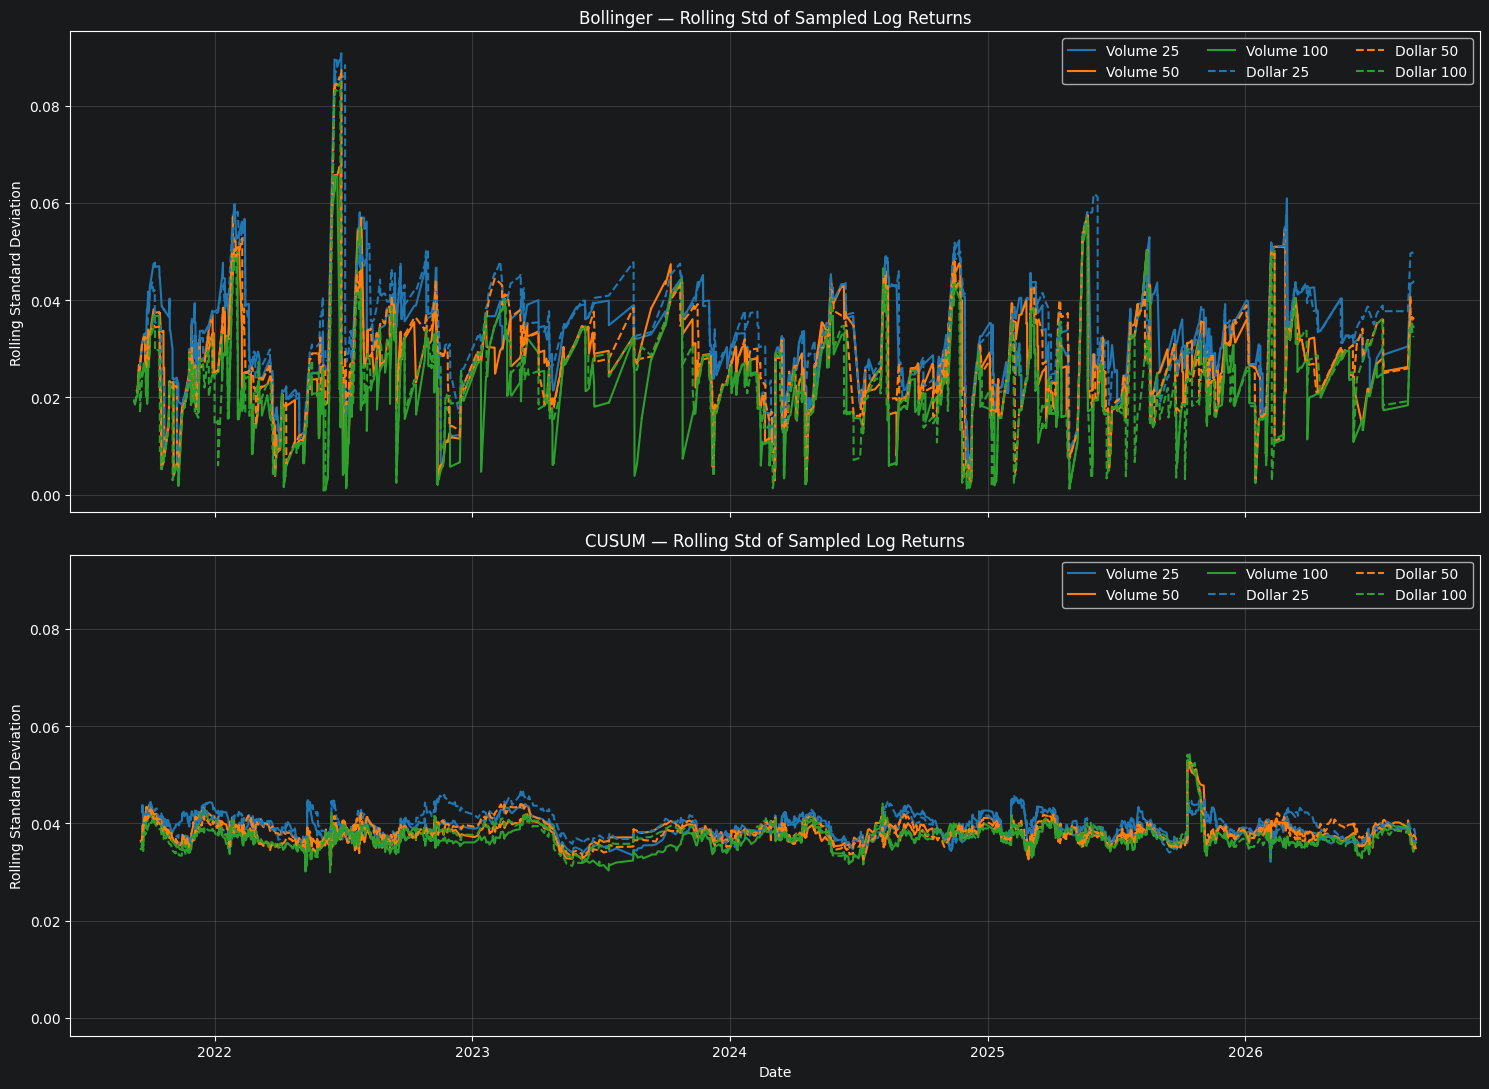

In [11]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 11),
    sharex=True,
    sharey=True
)

for ax, method in zip(axes, ["Bollinger", "CUSUM"]):

    for name in datasets:
        target = int(name.split()[-1])
        linestyle = "-" if name.startswith("Volume") else "--"

        result = rolling_results[(name, method)]

        ax.plot(
            result.index,
            result["rolling_std"],
            color=colors[target],
            linestyle=linestyle,
            linewidth=1.5,
            label=name
        )

    ax.set_title(f"{method} — Rolling Std of Sampled Log Returns")
    ax.set_ylabel("Rolling Standard Deviation")
    ax.legend(ncol=3)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

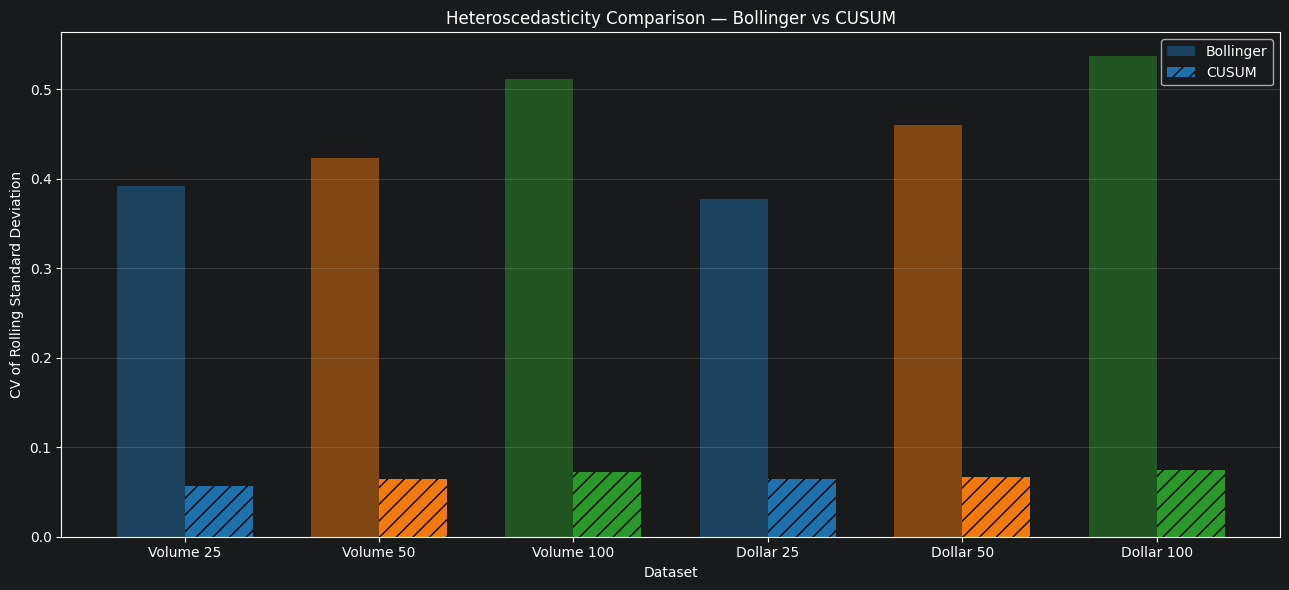


Coefficient of Variation (lower = more stable):
Method      Bollinger   CUSUM
Dataset                      
Dollar 100     0.5365  0.0744
Dollar 25      0.3771  0.0642
Dollar 50      0.4597  0.0662
Volume 100     0.5107  0.0721
Volume 25      0.3914  0.0566
Volume 50      0.4233  0.0650

Method with lower CV per dataset:
Dataset
Dollar 100    CUSUM
Dollar 25     CUSUM
Dollar 50     CUSUM
Volume 100    CUSUM
Volume 25     CUSUM
Volume 50     CUSUM


In [12]:
cv_comparison = hetero_summary["CV"].unstack("Method")

fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(len(datasets))
width = 0.35

for i, name in enumerate(datasets):
    target = int(name.split()[-1])

    ax.bar(
        x[i] - width / 2,
        cv_comparison.loc[name, "Bollinger"],
        width,
        color=colors[target],
        alpha=0.45,
        label="Bollinger" if i == 0 else None
    )

    ax.bar(
        x[i] + width / 2,
        cv_comparison.loc[name, "CUSUM"],
        width,
        color=colors[target],
        alpha=0.95,
        hatch="//",
        label="CUSUM" if i == 0 else None
    )

ax.set_xticks(x)
ax.set_xticklabels(datasets.keys())

ax.set_title("Heteroscedasticity Comparison — Bollinger vs CUSUM")
ax.set_xlabel("Dataset")
ax.set_ylabel("CV of Rolling Standard Deviation")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nCoefficient of Variation (lower = more stable):")
print(cv_comparison.round(4).to_string())

print("\nMethod with lower CV per dataset:")
print(
    cv_comparison.apply(
        lambda row: row.idxmin()
        if row.notna().any()
        else "Insufficient data",
        axis=1
    ).to_string()
)

## Computing de CUSUM filter, where {yt} are absolute returns and h = 0.05

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

H = 0.05

def cusum_absolute_returns(df, h=0.05):
    data = df.sort_values(
        ["segment_id", "bar_seq"],
        kind="stable"
    ).copy()

    close = pd.to_numeric(data["close"], errors="coerce")
    log_close = np.log(close.where(close > 0))

    # Absolute log returns within continuous segments
    abs_returns = (
        log_close.groupby(
            data["segment_id"].to_numpy(),
            sort=False
        )
        .diff()
        .abs()
        .to_numpy()
    )

    events = np.zeros(len(data), dtype=bool)
    accumulated = np.full(len(data), np.nan)

    segments = data["segment_id"].to_numpy()
    s_pos = 0.0

    for i, r in enumerate(abs_returns):

        # Reset at segment boundaries
        if i == 0 or segments[i] != segments[i - 1]:
            s_pos = 0.0

        if not np.isfinite(r):
            s_pos = 0.0
            continue

        # CUSUM on ABSOLUTE returns
        s_pos = max(0.0, s_pos + r)
        accumulated[i] = s_pos

        if s_pos > h:
            events[i] = True
            s_pos = 0.0

    event_log = pd.DataFrame({
        "close": close.to_numpy(),
        "abs_return": abs_returns,
        "accumulated_abs_return": accumulated,
        "event": events
    }, index=data.index).sort_index(kind="stable")

    sampled_bars = data.iloc[np.flatnonzero(events)].copy()

    return sampled_bars, event_log


abs_cusum_samples = {}
abs_cusum_logs = {}
summary_rows = []

for name, df in datasets.items():

    samples, log = cusum_absolute_returns(df, H)

    abs_cusum_samples[name] = samples
    abs_cusum_logs[name] = log

    summary_rows.append({
        "Dataset": name,
        "Original Bars": len(df),
        "CUSUM Samples": len(samples),
        "Sampled (%)": 100 * len(samples) / len(df),
        "Avg Events/Day": (
            log["event"].resample("D").sum().mean()
        )
    })

abs_cusum_summary = pd.DataFrame(
    summary_rows
).set_index("Dataset")

print("CUSUM on Absolute Log Returns (h = 0.05)\n")
print(abs_cusum_summary.round(3).to_string())

CUSUM on Absolute Log Returns (h = 0.05)

            Original Bars  CUSUM Samples  Sampled (%)  Avg Events/Day
Dataset                                                              
Volume 25          149245           8786        5.887           4.812
Volume 50          298201          12599        4.225           6.900
Volume 100         595326          17871        3.002           9.787
Dollar 25          147163           8609        5.850           4.715
Dollar 50          294042          12333        4.194           6.754
Dollar 100         594869          17635        2.965           9.658


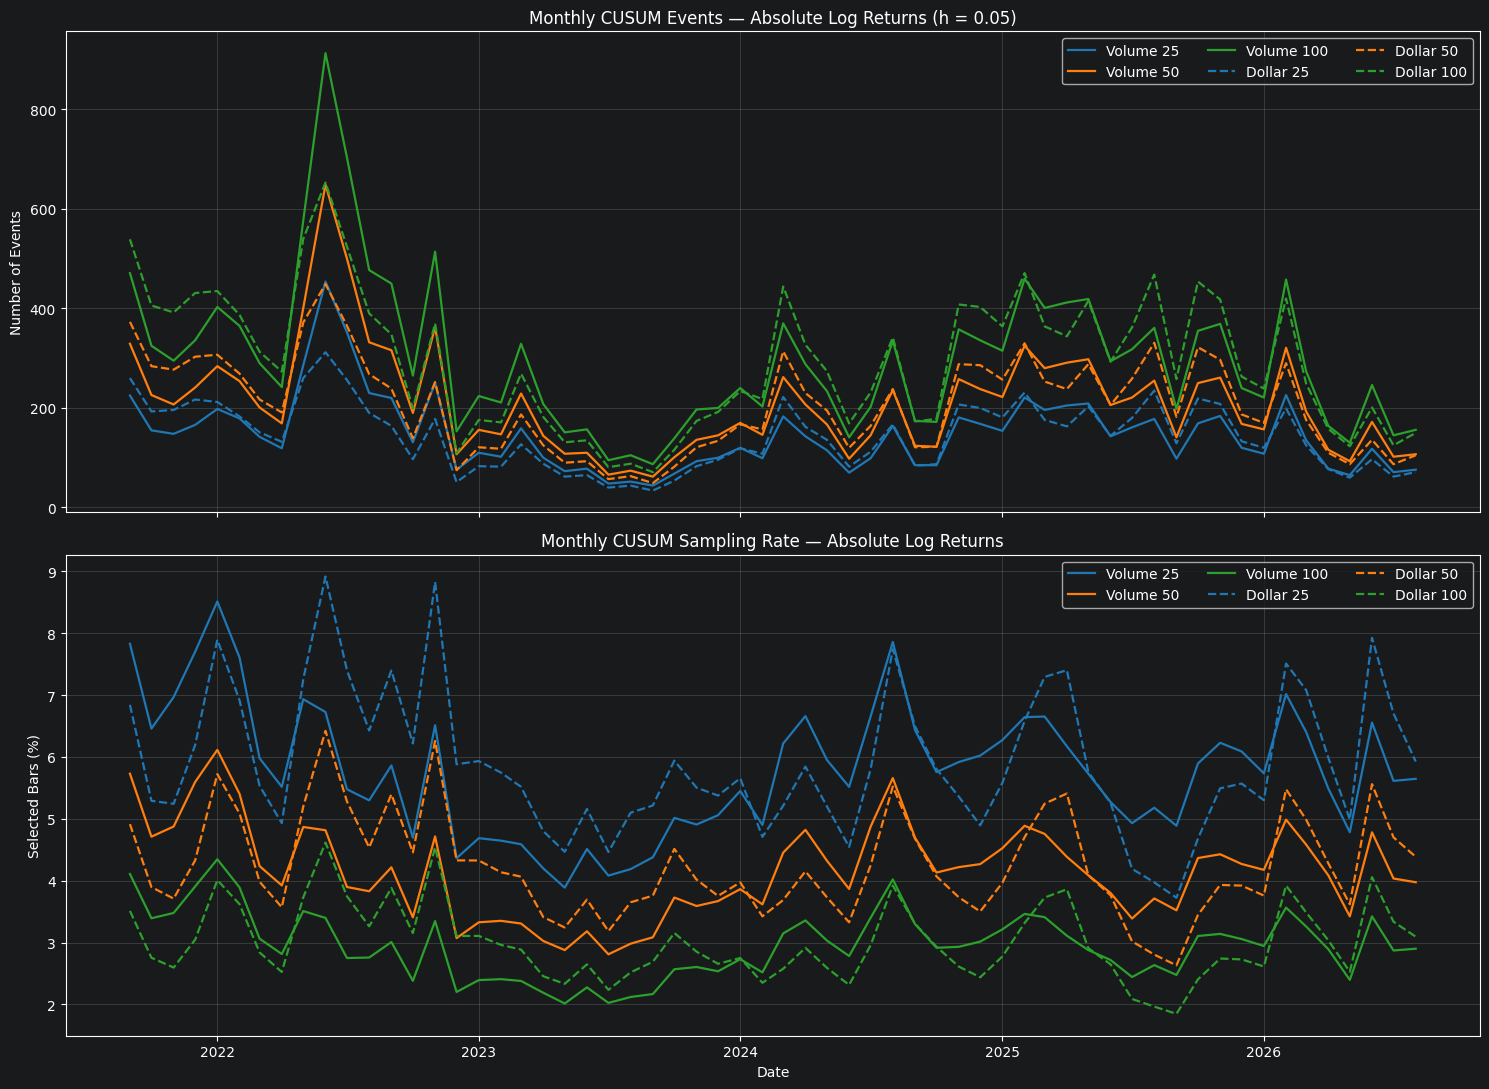

In [14]:
monthly_abs_events = pd.DataFrame({
    name: log["event"].resample("MS").sum()
    for name, log in abs_cusum_logs.items()
})

monthly_abs_rates = pd.DataFrame({
    name: (
        100 * log["event"].resample("MS").sum()
        / log["event"].resample("MS").size().replace(0, np.nan)
    )
    for name, log in abs_cusum_logs.items()
})

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 11),
    sharex=True
)

for name in datasets:
    target = int(name.split()[-1])
    linestyle = "-" if name.startswith("Volume") else "--"

    axes[0].plot(
        monthly_abs_events.index,
        monthly_abs_events[name],
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.6,
        label=name
    )

    axes[1].plot(
        monthly_abs_rates.index,
        monthly_abs_rates[name],
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.6,
        label=name
    )

axes[0].set_title(
    "Monthly CUSUM Events — Absolute Log Returns (h = 0.05)"
)
axes[1].set_title(
    "Monthly CUSUM Sampling Rate — Absolute Log Returns"
)

axes[0].set_ylabel("Number of Events")
axes[1].set_ylabel("Selected Bars (%)")

for ax in axes:
    ax.legend(ncol=3)
    ax.grid(True, alpha=0.3)

axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROLLING_WINDOW = 30

sampling_methods = {
    "Signed Returns": cusum_samples,
    "Absolute Returns": abs_cusum_samples,
}


def compute_sampled_rolling_std(df, window=30):
    data = df[
        ["close", "segment_id", "bar_seq"]
    ].sort_values(
        ["segment_id", "bar_seq"],
        kind="stable"
    ).copy()

    data["log_close"] = np.log(
        pd.to_numeric(data["close"], errors="coerce")
        .where(lambda x: x > 0)
    )

    # Log returns BETWEEN consecutive CUSUM-selected bars
    data["returns"] = (
        data.groupby("segment_id", sort=False)["log_close"]
        .diff()
    )

    # Rolling standard deviation within continuous segments
    data["rolling_std"] = (
        data.groupby("segment_id", sort=False)["returns"]
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).std(ddof=1)
        )
    )

    return data.sort_index(kind="stable")


rolling_cusum_results = {}
summary_rows = []

for method, samples_dict in sampling_methods.items():
    for name, samples in samples_dict.items():

        result = compute_sampled_rolling_std(
            samples, ROLLING_WINDOW
        )

        rolling_cusum_results[(method, name)] = result

        rolling_std = result["rolling_std"].dropna()

        mean_std = rolling_std.mean()
        std_of_std = rolling_std.std(ddof=1)

        summary_rows.append({
            "Dataset": name,
            "Method": method,
            "Samples": len(samples),
            "Valid Windows": len(rolling_std),
            "Mean Rolling Std": mean_std,
            "Std of Rolling Std": std_of_std,
            "CV": (
                std_of_std / mean_std
                if mean_std > 0 else np.nan
            )
        })

cusum_hetero_summary = pd.DataFrame(summary_rows).set_index(
    ["Dataset", "Method"]
)

print("CUSUM Rolling Standard Deviation Comparison\n")
print(cusum_hetero_summary.round(6).to_string())

CUSUM Rolling Standard Deviation Comparison

                             Samples  Valid Windows  Mean Rolling Std  Std of Rolling Std        CV
Dataset    Method                                                                                  
Volume 25  Signed Returns       1626           1596          0.039338            0.002225  0.056558
Volume 50  Signed Returns       1734           1704          0.038272            0.002488  0.064998
Volume 100 Signed Returns       1815           1785          0.037113            0.002676  0.072105
Dollar 25  Signed Returns       1621           1591          0.039819            0.002555  0.064171
Dollar 50  Signed Returns       1721           1691          0.038449            0.002547  0.066248
Dollar 100 Signed Returns       1812           1782          0.037602            0.002799  0.074429
Volume 25  Absolute Returns     8786           8756          0.016526            0.002962  0.179254
Volume 50  Absolute Returns    12599          12569    

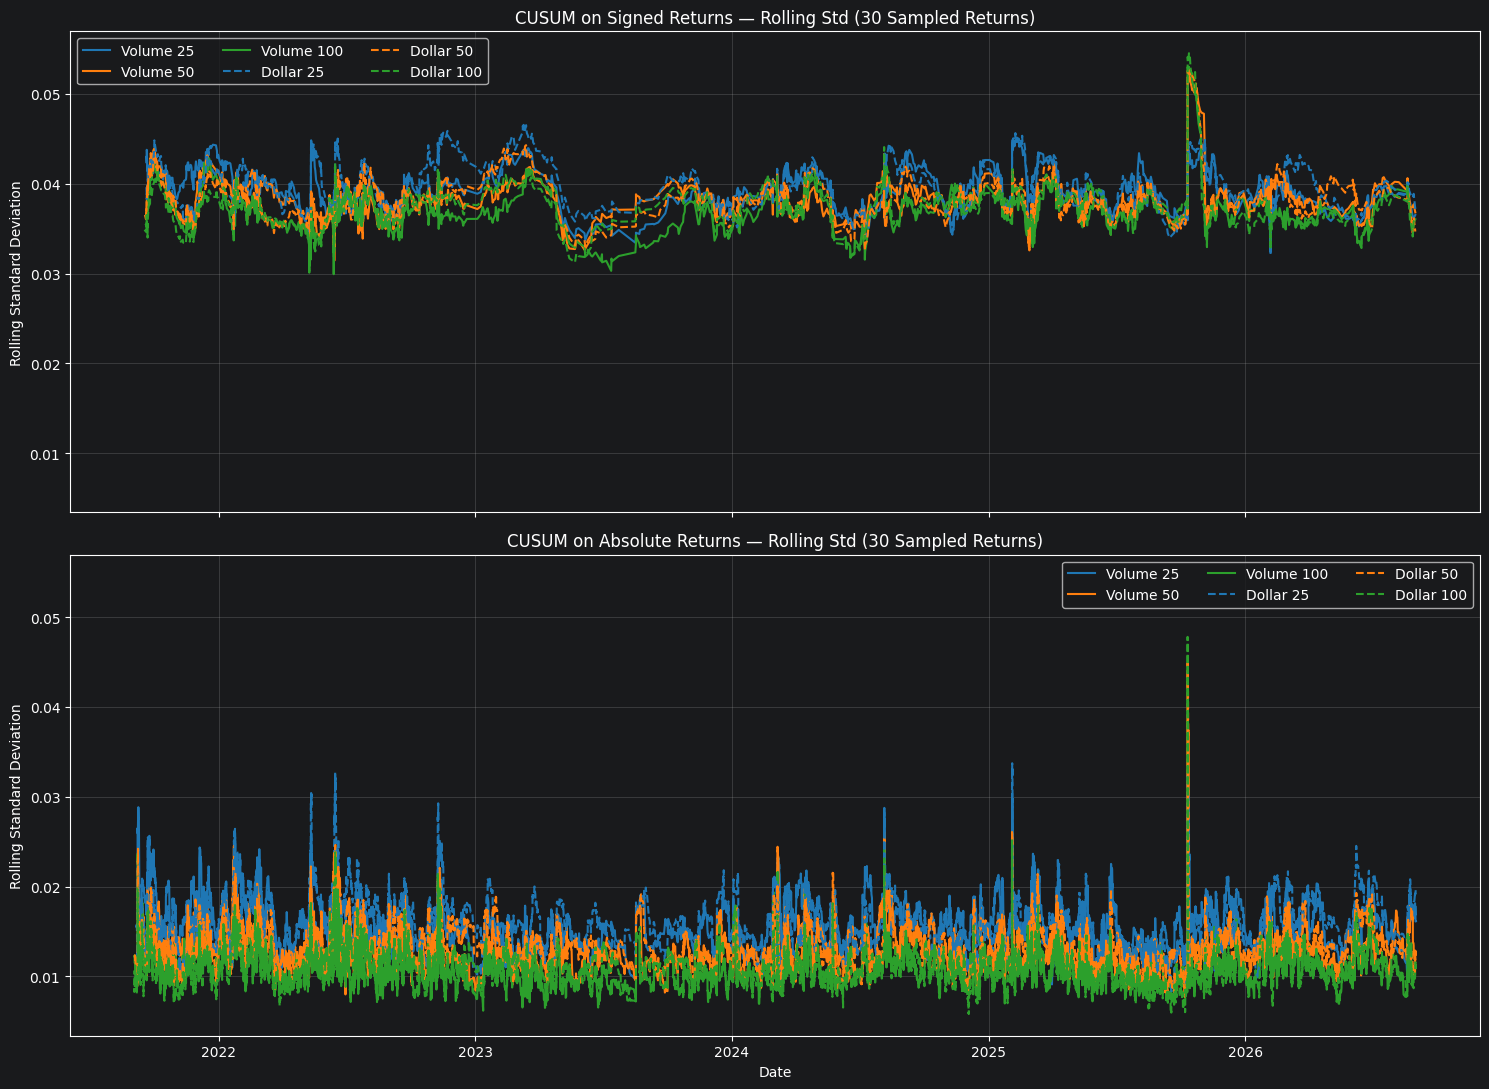

In [17]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 11),
    sharex=True,
    sharey=True
)

for ax, method in zip(axes, sampling_methods):

    for name in datasets:
        target = int(name.split()[-1])
        linestyle = "-" if name.startswith("Volume") else "--"

        result = rolling_cusum_results[(method, name)]

        ax.plot(
            result.index,
            result["rolling_std"],
            color=colors[target],
            linestyle=linestyle,
            linewidth=1.5,
            label=name
        )

    ax.set_title(
        f"CUSUM on {method} — Rolling Std "
        f"({ROLLING_WINDOW} Sampled Returns)"
    )
    ax.set_ylabel("Rolling Standard Deviation")
    ax.legend(ncol=3)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [16]:
comparison = cusum_hetero_summary[
    ["Samples", "Mean Rolling Std", "CV"]
].unstack("Method")

print(
    comparison.round(5).to_string()
)

                    Samples                Mean Rolling Std                              CV               
Method     Absolute Returns Signed Returns Absolute Returns Signed Returns Absolute Returns Signed Returns
Dataset                                                                                                   
Dollar 100            17635           1812          0.01162        0.03760          0.23899        0.07443
Dollar 25              8609           1621          0.01649        0.03982          0.21163        0.06417
Dollar 50             12333           1721          0.01379        0.03845          0.22115        0.06625
Volume 100            17871           1815          0.01151        0.03711          0.21964        0.07210
Volume 25              8786           1626          0.01653        0.03934          0.17925        0.05656
Volume 50             12599           1734          0.01383        0.03827          0.19869        0.06500


volume_25   bare= 149,244  2021-09-01 -> 2026-08-31  bare/zi=   81.8  durată mediană=  12.1 min  segmente=1  high/low=da  evenimente=1,623 (0.89/zi, +50%)
   atenție: orizonturile ['15min'] sunt sub 2x durata mediană a barei -> interpretează-le cu grijă
volume_50   bare= 298,167  2021-09-01 -> 2026-08-31  bare/zi=  163.5  durată mediană=   5.8 min  segmente=1  high/low=da  evenimente=1,731 (0.95/zi, +50%)
volume_100  bare= 594,951  2021-09-01 -> 2026-08-31  bare/zi=  326.2  durată mediană=   2.8 min  segmente=1  high/low=da  evenimente=1,812 (0.99/zi, +50%)
dollar_25   bare= 147,161  2021-09-01 -> 2026-08-31  bare/zi=   80.7  durată mediană=  11.8 min  segmente=1  high/low=da  evenimente=1,618 (0.89/zi, +50%)
   atenție: orizonturile ['15min'] sunt sub 2x durata mediană a barei -> interpretează-le cu grijă
dollar_50   bare= 294,017  2021-09-01 -> 2026-08-31  bare/zi=  161.2  durată mediană=   5.7 min  segmente=1  high/low=da  evenimente=1,719 (0.94/zi, +50%)
dollar_100  bare= 594,330  

,dataset,H,n_ev,bare_în_fereastră,med|z|_ev,med|z|_volm,ratio_volm,ratio_rand,ratio_triv,p_shift_mag,MW_p,KS,AD_p,P|z|>2_ev,P|z|>2_ev_CI,P|z|>2_volm,mean_sz,mean_sz_CI,hit,p_shift_dir,triv_mean_sz,fav/adv_mean,P(fav_first)
0,volume_25,15min,1623,3.0,0.962,0.283,3.402,5.334,0.807,0.002,0.000,0.314,0.001,0.237,"[0.21,0.26]",0.092,0.103,"[-0.02,0.22]",0.442,0.004,0.040,1.390,0.486
1,volume_25,30min,1623,5.0,0.889,0.517,1.719,1.845,0.791,0.002,0.000,0.203,0.001,0.194,"[0.17,0.22]",0.091,0.054,"[-0.05,0.15]",0.451,0.116,-0.009,1.337,0.506
2,volume_25,1h,1623,9.0,0.848,0.565,1.502,1.541,0.847,0.002,0.000,0.174,0.001,0.171,"[0.15,0.19]",0.088,0.076,"[-0.02,0.17]",0.460,0.020,-0.042,1.337,0.531
3,volume_25,2h,1623,15.0,0.782,0.570,1.370,1.363,0.892,0.002,0.000,0.134,0.001,0.140,"[0.12,0.16]",0.084,0.060,"[-0.02,0.14]",0.470,0.070,-0.093,1.290,0.533
4,volume_25,4h,1623,24.0,0.693,0.550,1.259,1.249,0.879,0.002,0.000,0.101,0.001,0.123,"[0.11,0.14]",0.078,0.032,"[-0.04,0.11]",0.450,0.317,-0.049,1.244,0.545
5,volume_25,8h,1623,42.0,0.629,0.539,1.166,1.143,0.878,0.002,0.000,0.068,0.001,0.099,"[0.08,0.11]",0.072,0.048,"[-0.02,0.12]",0.464,0.134,-0.031,1.230,0.543
6,volume_25,24h,1623,110.0,0.609,0.565,1.077,1.015,0.954,0.180,0.004,0.041,0.004,0.076,"[0.06,0.09]",0.066,0.015,"[-0.04,0.07]",0.471,0.577,0.041,1.177,0.517
7,volume_50,15min,1731,7.0,1.088,0.547,1.990,2.114,0.888,0.002,0.000,0.252,0.001,0.247,"[0.22,0.27]",0.097,0.021,"[-0.09,0.14]",0.443,0.559,-0.021,1.299,0.537
8,volume_50,30min,1731,11.0,0.976,0.593,1.647,1.690,0.916,0.002,0.000,0.202,0.001,0.214,"[0.19,0.24]",0.092,-0.007,"[-0.11,0.10]",0.440,0.824,-0.052,1.281,0.561
9,volume_50,1h,1731,19.0,0.872,0.569,1.531,1.475,0.935,0.002,0.000,0.176,0.001,0.183,"[0.16,0.20]",0.084,0.055,"[-0.04,0.15]",0.453,0.114,-0.068,1.292,0.547


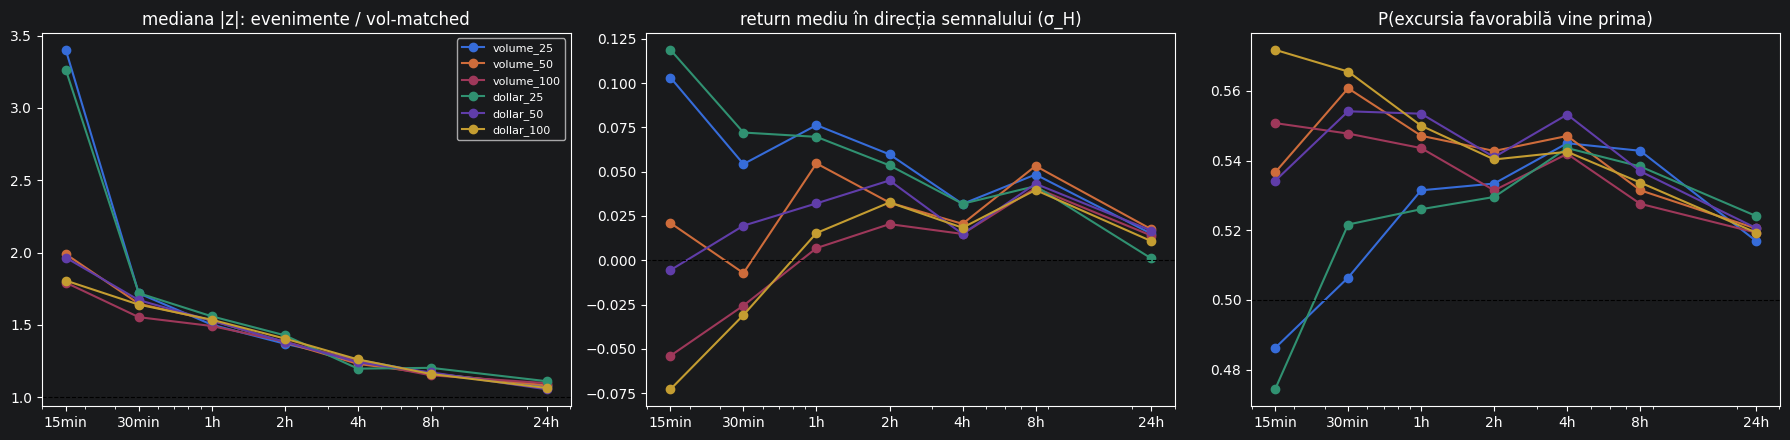

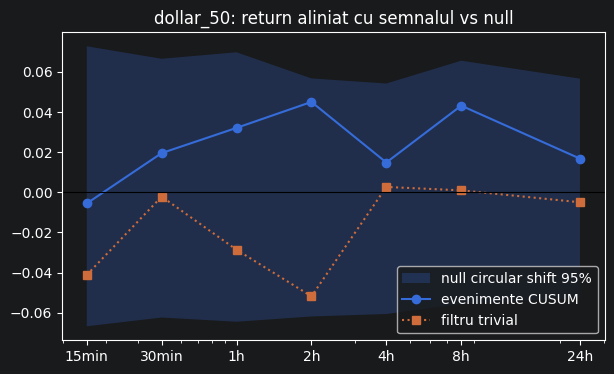

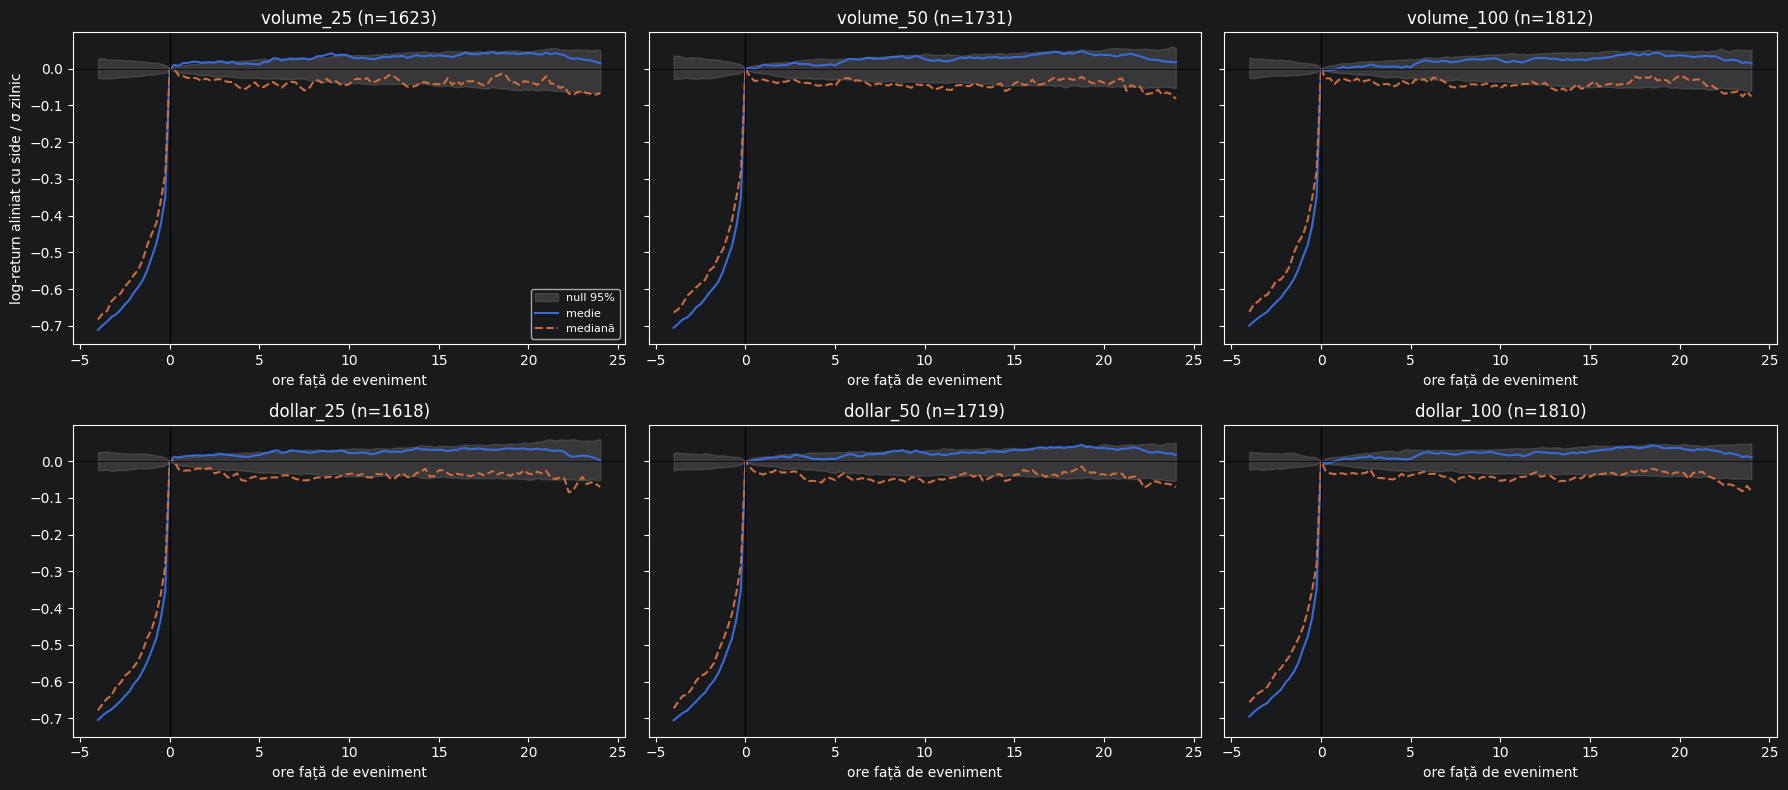

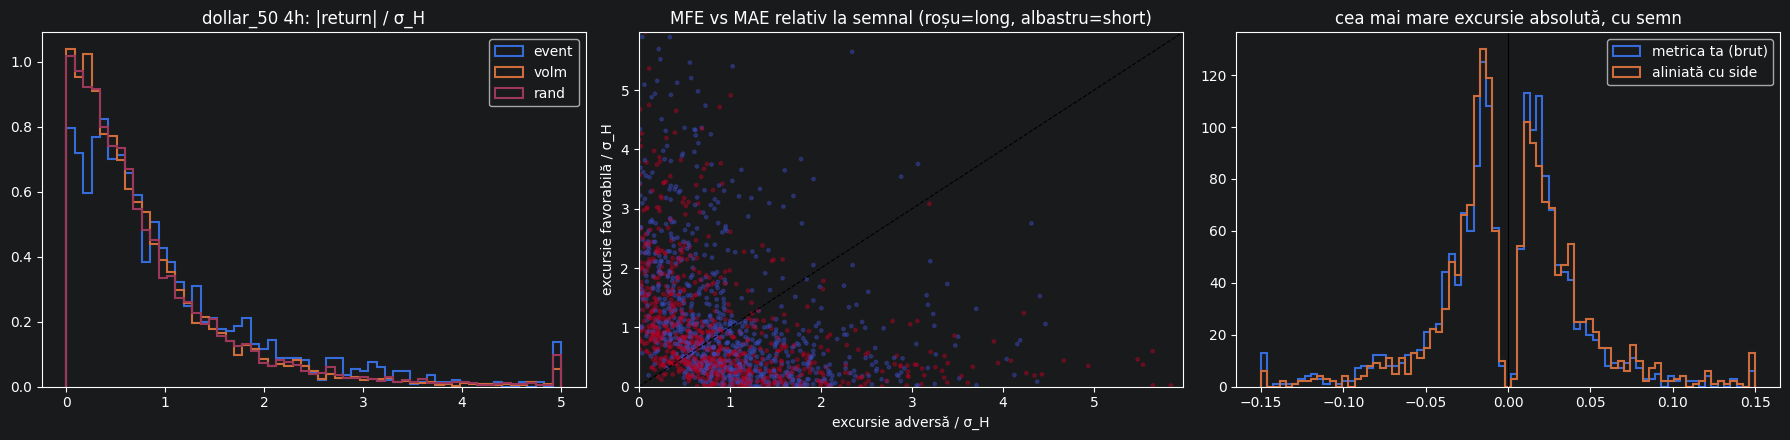

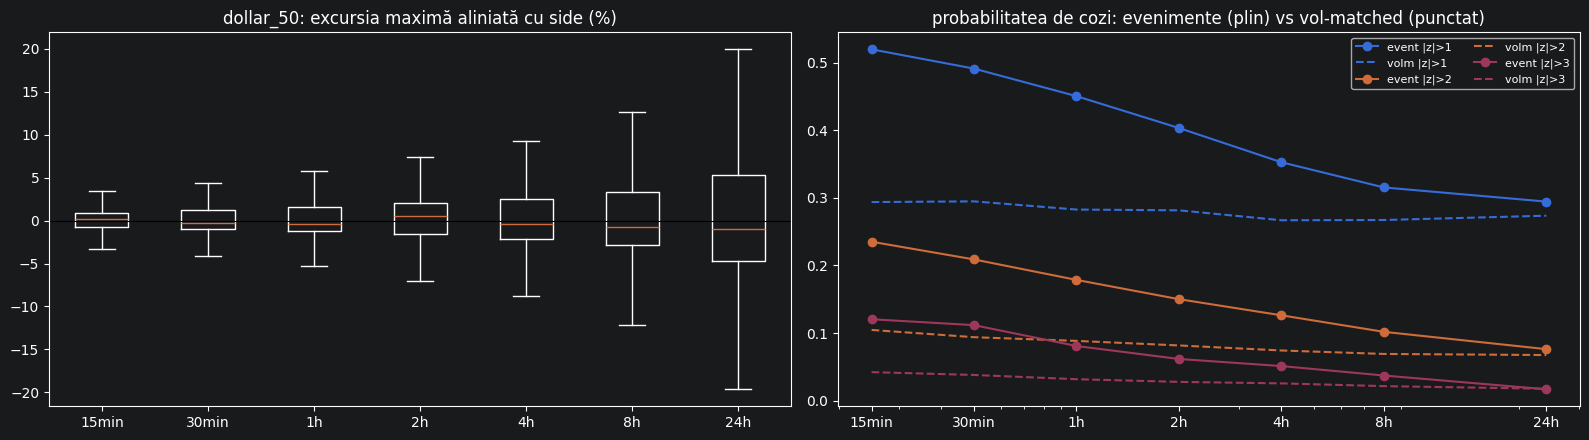

,dataset,H,n,HAC_lags,mag: coef_event,mag: t_event,mag: t_logσ,mag: R2,dir: coef_side,dir: t_side,dir: t_trail1h,dir: t_trail4h,dir: t_trail24h
0,volume_25,1h,149046,5,0.074,2.298,-21.637,0.074,0.020,0.438,2.285,1.055,0.106
1,volume_25,4h,149046,17,0.016,0.711,-17.447,0.041,-0.024,-0.784,1.363,0.756,1.009
2,volume_25,24h,149046,92,-0.019,-1.298,-12.376,0.046,-0.045,-2.216,1.304,0.673,0.997
3,volume_50,1h,297785,10,0.092,2.985,-21.768,0.071,0.006,0.145,2.334,0.326,0.143
4,volume_50,4h,297785,34,0.006,0.299,-15.634,0.039,-0.034,-1.156,1.465,0.514,0.977
5,volume_50,24h,297785,184,-0.031,-2.082,-11.685,0.042,-0.038,-1.947,1.133,0.693,0.898
6,volume_100,1h,594202,19,0.068,2.326,-19.500,0.067,-0.027,-0.641,1.590,0.460,-0.082
7,volume_100,4h,594202,67,0.016,0.789,-13.703,0.035,-0.035,-1.235,1.303,0.511,0.989
8,volume_100,24h,594202,366,-0.026,-1.822,-10.958,0.039,-0.040,-2.083,1.034,0.614,0.982
9,dollar_25,1h,146905,5,0.059,1.932,-20.675,0.073,0.003,0.071,2.770,1.311,-0.313


dollar_50: features la eveniment vs vol-matched (top 25 după KS)


,feature,n_ev,med_ev,med_volm,SMD,KS,MW_p
58,sadf_w200_tau30_p1_c,1719,3.051000e-01,-7.042000e-01,1.3376,0.5379,0.0000
60,cadf_q95_w200_tau30_p1_c,1719,2.138000e-01,-7.883000e-01,1.3352,0.5293,0.0000
59,qadf_q95_w200_tau30_p1_c,1719,1.441000e-01,-8.578000e-01,1.3220,0.5205,0.0000
66,csw_two_w200,1719,2.581800e+00,1.859700e+00,1.1473,0.4930,0.0000
22,volume_per_s,1718,4.512370e+01,9.701700e+00,0.0493,0.4456,0.0000
19,trade_span_s,1719,7.054670e+01,3.043550e+02,-0.7895,0.4369,0.0000
18,bar_duration_s,1719,7.054670e+01,3.043680e+02,-0.7895,0.4369,0.0000
87,dur_s,1719,7.054670e+01,3.043680e+02,-0.7895,0.4369,0.0000
23,notional_per_s,1718,1.063578e+05,2.471050e+04,0.0310,0.4368,0.0000
21,trade_intensity_per_s,1718,1.129262e+02,2.998650e+01,0.2209,0.3586,0.0000


,dataset,AUC,AUC_std,n_features
0,volume_25,0.920,0.019,88
1,volume_50,0.947,0.012,88
2,volume_100,0.966,0.009,88
3,dollar_25,0.915,0.011,88
4,dollar_50,0.949,0.016,88
5,dollar_100,0.964,0.011,88


,serie,n,skew,ex_kurt,JB,ac1_r,ac1_r2,cv2_monthly_var,LB10_p_r,LB10_p_r2
0,volume_25,148891,0.0198,2.6670,4.413669e+04,-0.0006,0.2663,0.1424,0.0320,0.0
1,volume_50,296765,0.1473,12.0612,1.799872e+06,-0.0062,0.3137,0.1512,0.0000,0.0
2,volume_100,589604,0.1581,28.7797,2.035051e+07,-0.0105,0.5095,0.1653,0.0000,0.0
3,dollar_25,146812,0.0883,7.3307,3.289239e+05,-0.0033,0.1841,0.1953,0.5437,0.0
4,dollar_50,292755,0.0485,13.3270,2.166612e+06,-0.0140,0.5301,0.1835,0.0000,0.0
5,dollar_100,589083,0.0672,53.5075,7.027447e+07,-0.0177,0.4951,0.2031,0.0000,0.0
6,time_15min,135677,-0.1917,20.3515,2.342288e+06,-0.0213,0.1380,0.2525,0.0000,0.0
7,time_1h,43283,-0.3561,14.4340,3.766486e+05,-0.0151,0.1436,0.3792,0.0024,0.0


,P(same_side),null_mean,null_q025,null_q975,binom_p_vs_0.5
volume_25,0.4898,0.4991,0.4863,0.5202,0.4273
volume_50,0.4939,0.4968,0.4790,0.5118,0.6309
volume_100,0.4967,0.5020,0.4835,0.5221,0.7962
dollar_25,0.4883,0.5007,0.4784,0.5191,0.3580
dollar_50,0.4855,0.5030,0.4894,0.5146,0.2374
dollar_100,0.4970,0.4992,0.4865,0.5124,0.8142


,dataset,n_ev,ev/zi,Δt_median_h,Δt_mean_h,CV_Δt (1=Poisson),dispersie zilnică (1=Poisson),uniqueness_4h,uniqueness_24h
0,volume_25,1623,0.890,16.539,26.934,1.297,1.998,0.884,0.609
1,volume_50,1731,0.949,15.287,25.253,1.341,2.214,0.869,0.586
2,volume_100,1812,0.993,14.251,24.123,1.375,2.435,0.861,0.570
3,dollar_25,1618,0.887,16.567,27.018,1.304,1.962,0.886,0.608
4,dollar_50,1719,0.942,15.561,25.462,1.339,2.211,0.871,0.590
5,dollar_100,1810,0.992,14.733,24.181,1.376,2.539,0.856,0.571


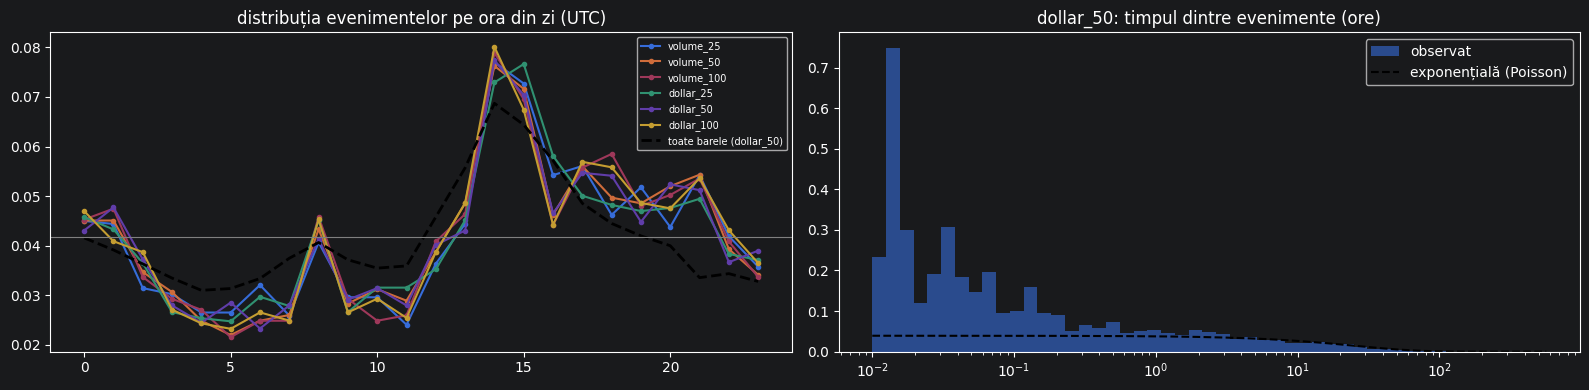

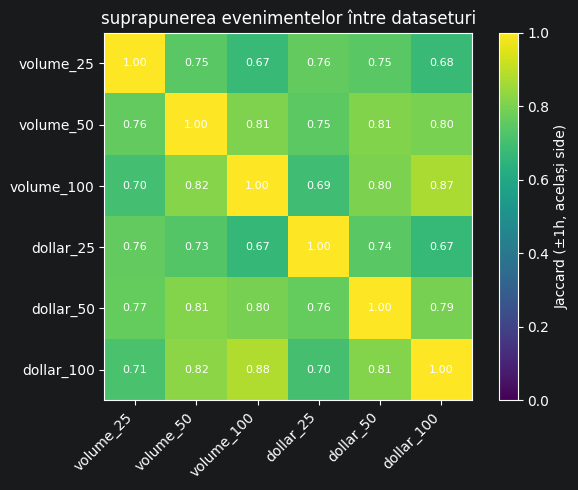

,year,dataset,n,mean_sz,hit,med_absz,fav_first,med_absz_volm,ratio_volm
0,2021,volume_25,154,-0.127,0.429,0.705,0.578,0.539,1.307
1,2022,volume_25,498,0.014,0.472,0.684,0.504,0.572,1.196
2,2023,volume_25,141,0.272,0.468,0.764,0.543,0.516,1.481
3,2024,volume_25,292,-0.073,0.401,0.688,0.589,0.536,1.282
4,2025,volume_25,377,0.113,0.480,0.692,0.525,0.586,1.182
5,2026,volume_25,161,0.028,0.410,0.685,0.609,0.509,1.346
6,2021,volume_50,163,-0.091,0.417,0.707,0.601,0.549,1.288
7,2022,volume_50,535,0.018,0.465,0.661,0.508,0.562,1.177
8,2023,volume_50,151,0.247,0.497,0.775,0.556,0.501,1.545
9,2024,volume_50,309,-0.064,0.405,0.677,0.579,0.564,1.201


,dataset,h,n_ev,ev/zi,ratio_volm,mean_sz,hit
0,volume_25,0.02,7780,4.266,1.190,0.015,0.465
1,volume_25,0.03,3974,2.179,1.218,0.012,0.452
2,volume_25,0.05,1623,0.890,1.211,0.032,0.450
3,volume_25,0.08,686,0.376,1.411,-0.021,0.448
4,volume_25,0.12,323,0.177,1.336,0.021,0.446
5,volume_50,0.02,8905,4.882,1.172,0.011,0.462
6,volume_50,0.03,4393,2.408,1.254,-0.000,0.449
7,volume_50,0.05,1731,0.949,1.232,0.021,0.451
8,volume_50,0.08,721,0.395,1.344,-0.010,0.444
9,volume_50,0.12,336,0.184,1.384,-0.032,0.423


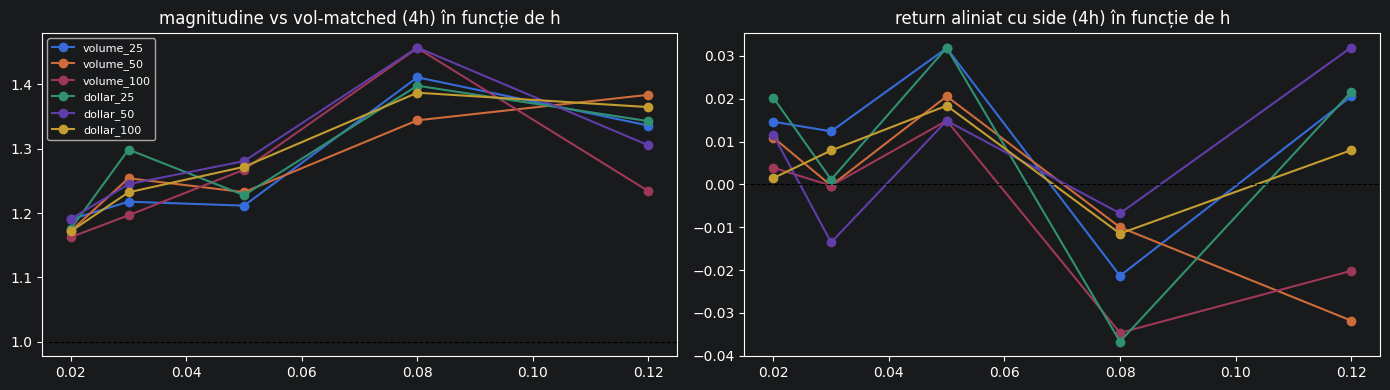

In [24]:
# %% [markdown]
# # Teste pe evenimentele CUSUM
# Presupune că în notebook există deja: volume_25, volume_50, volume_100, dollar_25, dollar_50, dollar_100
# (DataFrame-uri cu index datetime = închiderea barei, coloane OHLC, segment_id, bar_start_us, bar_end_us, ...).
#
# Ce face:
#  0. config + verificare coloane
#  1. CUSUM simetric pe log-returnuri (h = 0.05), ca în AFML
#  2. metrici forward pe mai multe orizonturi (în timp): return final, MFE/MAE din high/low, ordinea extremelor,
#     metrica ta originală (cea mai mare excursie absolută, cu semn) — totul normalizat la volatilitatea locală
#  3. baseline-uri: random, potrivit pe volatilitate (an x decilă σ), filtru trivial (șoc pe o bară)
#  4. teste: magnitudine (MW, KS, Anderson-Darling, cozi), direcție (bootstrap pe blocuri), null prin circular shift
#  5. event study cu bandă de null
#  6. regresie de valoare incrementală (HAC): aduce CUSUM ceva peste volatilitate și momentum?
#  7. features la momentul evenimentului + test de discriminare (AUC)
#  8. proprietăți statistice ale barelor (AFML cap. 2) + continuarea direcției între evenimente
#  9. structură temporală, unicitate medie, suprapunerea evenimentelor între dataseturi
# 10. stabilitate pe ani + sensibilitate la pragul h

# %% ==================== 0. CONFIG ====================
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    from IPython.display import display
except ImportError:  # rulare în afara notebook-ului
    display = print

try:
    import statsmodels.api as sm
    from statsmodels.stats.diagnostic import acorr_ljungbox
    HAS_SM = True
except ImportError:
    HAS_SM = False
    print("statsmodels lipsește -> regresiile HAC și Ljung-Box sunt sărite (pip install statsmodels)")

try:
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.metrics import roc_auc_score
    HAS_SK = True
except ImportError:
    HAS_SK = False
    print("scikit-learn lipsește -> testul de discriminare (AUC) e sărit")

try:
    import numba
    def _jit(f):
        return numba.njit(cache=False)(f)
except ImportError:
    def _jit(f):
        return f
    print("numba lipsește -> codul merge, doar mai încet (pip install numba)")

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

DATASETS = {
    "volume_25": volume_25, "volume_50": volume_50, "volume_100": volume_100,
    "dollar_25": dollar_25, "dollar_50": dollar_50, "dollar_100": dollar_100,
}

CUSUM_H = 0.05                       # pragul tău, pe log-returnuri
HORIZONS = ["15min", "30min", "1h", "2h", "4h", "8h", "24h"]   # orizonturi forward, în timp
MAIN_H = "4h"                        # orizontul pentru graficele detaliate
REF = "dollar_50"                    # datasetul pentru graficele detaliate
N_MATCH = 5                          # câte bare de baseline per eveniment
N_SHIFTS = 500                       # permutări circular shift pentru p-values
N_SHIFTS_ES = 200                    # permutări pentru banda din event study
N_BOOT = 1000                        # bootstrap pe blocuri
ES_BEFORE, ES_AFTER, ES_STEP = "4h", "24h", "15min"   # fereastra event study
H_GRID = [0.02, 0.03, 0.05, 0.08, 0.12]               # sensibilitate la prag
REG_HORIZONS = ["1h", "4h", "24h"]
REG_STRIDE = 1                       # pune 2-5 dacă regresiile sunt lente (multe bare)
SEED = 42

# Dacă ai deja evenimentele tale (algoritmul tău CUSUM), pune-le aici și vor fi folosite în loc de cele calculate:
#   OWN_EVENTS["dollar_50"] = pd.Series(side, index=timestamps)   # side = +1 / -1
#   sau doar un DatetimeIndex (side se deduce din semnul mișcării de la evenimentul anterior)
OWN_EVENTS = {}

# Numele coloanelor OHLC; None = autodetecție. Dacă nu le găsește, setează-le manual.
COLS = {"close": None, "high": None, "low": None}

rng = np.random.default_rng(SEED)

# %% ==================== 1. FUNCȚII DE BAZĂ ====================
_CAND = {
    "close": ["close", "close_price", "px_close", "price_close", "last_price", "last"],
    "high": ["high", "high_price", "px_high", "price_high", "max_price"],
    "low": ["low", "low_price", "px_low", "price_low", "min_price"],
}


def _col(df, key, required):
    if COLS.get(key):
        return COLS[key]
    for c in _CAND[key]:
        if c in df.columns:
            return c
    if required:
        raise KeyError(f"Nu găsesc coloana '{key}'. Setează COLS['{key}']. Coloane: {list(df.columns)}")
    return None


def td(x):
    """Timedelta -> nanosecunde (int)."""
    return pd.Timedelta(x).value


NS_H = td("1h")
NS_D = td("1D")


def to_ns(index_like):
    idx = pd.DatetimeIndex(index_like)
    if idx.tz is not None:
        idx = idx.tz_convert("UTC").tz_localize(None)
    return idx.values.astype("datetime64[ns]").astype(np.int64)


def prepare(df_raw):
    """Construiește array-urile necesare: log-close, returnuri, σ locală, ferestre forward."""
    df = df_raw.sort_index()
    df = df[~df.index.duplicated(keep="last")]
    ts = to_ns(df.index)
    idx = pd.DatetimeIndex(ts)  # naive UTC, ns
    c_close, c_high, c_low = _col(df, "close", True), _col(df, "high", False), _col(df, "low", False)
    close = df[c_close].to_numpy(float)
    high = df[c_high].to_numpy(float) if c_high else close.copy()
    low = df[c_low].to_numpy(float) if c_low else close.copy()
    n = len(df)

    # segmente (nu lăsăm ferestrele să treacă peste găuri în date)
    seg = df["segment_id"].to_numpy() if "segment_id" in df.columns else np.zeros(n, int)
    brk = np.flatnonzero(seg[1:] != seg[:-1])
    ends, starts = np.r_[brk, n - 1], np.r_[0, brk + 1]
    run = np.repeat(np.arange(len(ends)), ends - starts + 1)
    s_end, s_start = ends[run], starts[run]

    logc = np.log(close)
    r = np.zeros(n)
    r[1:] = np.diff(logc)
    r[starts] = 0.0

    # σ zilnică locală = sqrt(varianța realizată pe ultimele 24h), cauzală, comparabilă între tipuri de bare
    rv = pd.Series(r ** 2, index=idx).rolling("24h").sum().to_numpy()
    sig = np.sqrt(rv)
    sig[(ts - ts[s_start]) < NS_D] = np.nan
    sig[~(sig > 0)] = np.nan

    if {"bar_start_us", "bar_end_us"} <= set(df.columns):
        dur = (df["bar_end_us"].to_numpy(float) - df["bar_start_us"].to_numpy(float)) / 1e6
    else:
        dur = np.r_[np.nan, np.diff(ts) / 1e9]
    sig_bar = pd.Series(r).ewm(span=100, min_periods=50).std().shift(1).to_numpy()

    b = dict(df=df, idx=idx, ts=ts, close=close, high=high, low=low, logc=logc, r=r, sig=sig,
             sig_bar=sig_bar, dur=dur, s_start=s_start, s_end=s_end, n=n,
             has_hl=(c_high is not None and c_low is not None), fwd={}, j={})
    for H in HORIZONS:
        tgt = ts + td(H)
        j = np.minimum(np.searchsorted(ts, tgt, side="right") - 1, s_end)
        f = logc[j] - logc
        f[ts[s_end] < tgt] = np.nan          # fereastră incompletă
        b["fwd"][H], b["j"][H] = f, j
    hmax = max(HORIZONS, key=td)
    b["elig"] = np.isfinite(sig) & np.isfinite(b["fwd"][hmax])
    return b


def sig_h(b, H):
    """σ pe orizontul H, din σ zilnică (scalare sqrt(t))."""
    return b["sig"] * np.sqrt(td(H) / NS_D)


def trailing(b, tau):
    """Log-return pe ultimele tau (cauzal)."""
    back = b["ts"] - td(tau)
    k = np.maximum(np.searchsorted(b["ts"], back, side="right") - 1, 0)
    out = b["logc"] - b["logc"][k]
    out[back < b["ts"][b["s_start"]]] = np.nan
    return out


def _cusum_core(r, h):
    n = r.shape[0]
    ev = np.zeros(n, np.int8)
    sp, sn = 0.0, 0.0
    for i in range(1, n):
        x = r[i]
        sp = max(0.0, sp + x)
        sn = min(0.0, sn + x)
        if sn < -h:
            sn = 0.0
            ev[i] = -1
        elif sp > h:
            sp = 0.0
            ev[i] = 1
    return ev


_cusum = _jit(_cusum_core)


def get_events(name, b, h=CUSUM_H):
    """Poziții (în bare) și side (+1/-1) ale evenimentelor, doar pe barele eligibile."""
    if name in OWN_EVENTS and h == CUSUM_H:
        own = OWN_EVENTS[name]
        t = own.index if isinstance(own, pd.Series) else own
        pos = np.searchsorted(b["ts"], to_ns(t), side="right") - 1
        ok = pos >= 0
        pos = pos[ok]
        if isinstance(own, pd.Series):
            side = np.sign(own.to_numpy(float))[ok]
        else:
            prev = np.r_[0, pos[:-1]]
            side = np.sign(b["logc"][pos] - b["logc"][prev])
            side[side == 0] = 1.0
    else:
        ev = _cusum(b["r"], float(h))
        pos = np.flatnonzero(ev)
        side = ev[pos].astype(float)
    keep = b["elig"][pos]
    return pos[keep].astype(np.int64), side[keep]


def _exc_core(high, low, close, anchors, js):
    m = anchors.shape[0]
    out = np.full((m, 4), np.nan)
    for q in range(m):
        i = anchors[q]
        j = js[q]
        if j <= i:
            out[q, 0] = 0.0
            out[q, 1] = 0.0
            continue
        bu = i + 1
        bd = i + 1
        hu = high[i + 1]
        ld = low[i + 1]
        for k in range(i + 2, j + 1):
            if high[k] > hu:
                hu = high[k]
                bu = k
            if low[k] < ld:
                ld = low[k]
                bd = k
        out[q, 0] = max(0.0, np.log(hu / close[i]))
        out[q, 1] = min(0.0, np.log(ld / close[i]))
        out[q, 2] = bu
        out[q, 3] = bd
    return out


_exc = _jit(_exc_core)


def anchor_metrics(b, anchors, side, label):
    """Metrici forward pentru un set de bare-ancoră, pe toate orizonturile."""
    anchors = np.asarray(anchors, np.int64)
    side = np.asarray(side, float)
    out = []
    for H in HORIZONS:
        j = b["j"][H][anchors].astype(np.int64)
        ex = _exc(b["high"], b["low"], b["close"], anchors, j)
        sH = sig_h(b, H)[anchors]
        f = b["fwd"][H][anchors]
        mfe, mae = ex[:, 0], ex[:, 1]
        iu = np.where(mfe > 0, ex[:, 2], np.inf)
        idn = np.where(mae < 0, ex[:, 3], np.inf)
        up_first = np.where(iu < idn, 1.0, np.where(idn < iu, 0.0, np.nan))
        mas = np.where(mfe >= -mae, mfe, mae)      # metrica ta: cea mai mare excursie absolută, cu semn
        d = pd.DataFrame({
            "set": label, "H": H, "pos": anchors, "t": b["ts"][anchors], "side": side,
            "fwd": f, "z": f / sH, "absz": np.abs(f) / sH,
            "mfe": mfe, "mae": mae, "mfe_z": mfe / sH, "mae_z": -mae / sH, "mas": mas,
        })
        d["sz"] = side * d["z"]                                                   # return aliniat cu semnalul
        d["fav_z"] = np.where(side > 0, d["mfe_z"], np.where(side < 0, d["mae_z"], np.nan))
        d["adv_z"] = np.where(side > 0, d["mae_z"], np.where(side < 0, d["mfe_z"], np.nan))
        d["fav_first"] = np.where(side > 0, up_first, np.where(side < 0, 1 - up_first, np.nan))
        d["mas_side"] = side * mas
        out.append(d)
    return pd.concat(out, ignore_index=True)


def baselines(b, ev_pos, ev_side):
    """random / potrivit pe volatilitate (an x decilă σ) / filtru trivial (șoc pe o bară)."""
    elig = np.flatnonzero(b["elig"])
    non = np.setdiff1d(elig, ev_pos)
    n_ev = len(ev_pos)
    sets = {"event": (ev_pos, ev_side)}
    sets["rand"] = (rng.choice(non, size=N_MATCH * n_ev, replace=True), np.full(N_MATCH * n_ev, np.nan))

    ls = np.log(b["sig"])
    qs = np.nanquantile(ls[elig], np.linspace(0, 1, 11)[1:-1])
    dec = np.digitize(ls, qs)
    key = b["idx"].year.to_numpy() * 100 + dec
    picks = []
    for keys in (key, dec):                       # întâi an x decilă, fallback doar decilă
        nk = keys[non]
        o = np.argsort(nk, kind="stable")
        picks.append((nk[o], non[o]))
    out = np.empty((n_ev, N_MATCH), np.int64)
    for q, e in enumerate(ev_pos):
        for (nk_s, non_s), kv in zip(picks, (key[e], dec[e])):
            lo, hi = np.searchsorted(nk_s, kv), np.searchsorted(nk_s, kv, side="right")
            if hi > lo:
                out[q] = non_s[rng.integers(lo, hi, N_MATCH)]
                break
        else:
            out[q] = rng.choice(non, N_MATCH)
    sets["volm"] = (out.ravel(), np.full(out.size, np.nan))

    zr = np.abs(b["r"]) / b["sig_bar"]
    zr[~b["elig"]] = -np.inf
    zr[~np.isfinite(zr)] = -np.inf
    top = np.sort(np.argpartition(-zr, n_ev)[:n_ev])
    sets["trivial"] = (top.astype(np.int64), np.sign(b["r"][top]))
    return sets


def shifted_anchors(b, ev_pos, n_shift):
    elig = np.flatnonzero(b["elig"])
    m = len(elig)
    p = np.searchsorted(elig, ev_pos)
    offs = rng.integers(int(0.05 * m), int(0.95 * m), n_shift)
    return elig[(p[None, :] + offs[:, None]) % m]          # (n_shift, n_ev)


def shift_null(b, ev_pos, ev_side):
    """Null prin circular shift: păstrează numărul, clustering-ul și secvența side a evenimentelor."""
    A = shifted_anchors(b, ev_pos, N_SHIFTS)
    res = {}
    for H in HORIZONS:
        Z = (b["fwd"][H] / sig_h(b, H))[A]
        res[H] = dict(med_abs=np.nanmedian(np.abs(Z), 1), mean_sz=np.nanmean(Z * ev_side[None, :], 1))
    return res


def block_mean_ci(vals, t_ns, block_ns, n_boot=N_BOOT):
    """CI 95% pentru o medie, bootstrap pe blocuri de timp (corectează suprapunerea ferestrelor)."""
    vals = np.asarray(vals, float)
    ok = np.isfinite(vals)
    vals, t = vals[ok], np.asarray(t_ns)[ok]
    if len(vals) < 10:
        return np.nan, np.nan
    _, inv = np.unique((t - t.min()) // block_ns, return_inverse=True)
    S = np.bincount(inv, weights=vals)
    C = np.bincount(inv).astype(float)
    pick = rng.integers(0, len(S), size=(n_boot, len(S)))
    bs = S[pick].sum(1) / C[pick].sum(1)
    return tuple(np.quantile(bs, [0.025, 0.975]))


def event_paths(b, anchors, side, offsets_ns):
    """Traiectorii log-preț aliniate cu side, în unități de σ zilnică."""
    tgt = b["ts"][anchors][:, None] + offsets_ns[None, :]
    k = np.clip(np.searchsorted(b["ts"], tgt, side="right") - 1, 0, b["n"] - 1)
    ok = (tgt >= b["ts"][b["s_start"][anchors]][:, None]) & (tgt <= b["ts"][b["s_end"][anchors]][:, None])
    P = (b["logc"][k] - b["logc"][anchors][:, None]) * side[:, None] / b["sig"][anchors][:, None]
    P[~ok] = np.nan
    return P


# %% ==================== 2. VERIFICARE DATE + CALCUL ====================
R = {}
for name, df in DATASETS.items():
    b = prepare(df)
    ev_pos, ev_side = get_events(name, b)
    days = (b["ts"][b["elig"]][-1] - b["ts"][b["elig"]][0]) / NS_D
    med_dur = np.nanmedian(b["dur"])
    print(f"{name:11s} bare={b['n']:>8,d}  {pd.Timestamp(b['ts'][0]).date()} -> {pd.Timestamp(b['ts'][-1]).date()}  "
          f"bare/zi={b['n'] / max(days, 1):7.1f}  durată mediană={med_dur / 60:6.1f} min  "
          f"segmente={len(np.unique(b['s_start']))}  high/low={'da' if b['has_hl'] else 'NU (folosesc close)'}  "
          f"evenimente={len(ev_pos):,d} ({len(ev_pos) / max(days, 1):.2f}/zi, +{(ev_side > 0).mean():.0%})")
    short = [H for H in HORIZONS if td(H) < 2 * med_dur * 1e9]
    if short:
        print(f"   atenție: orizonturile {short} sunt sub 2x durata mediană a barei -> interpretează-le cu grijă")
    sets = baselines(b, ev_pos, ev_side)
    M = pd.concat([anchor_metrics(b, a, s, lab) for lab, (a, s) in sets.items()], ignore_index=True)
    R[name] = dict(b=b, ev_pos=ev_pos, ev_side=ev_side, sets=sets, M=M, null=shift_null(b, ev_pos, ev_side), days=days)

# %% ==================== 3. TABEL PRINCIPAL: EVENIMENTE vs BASELINE, PE ORIZONTURI ====================
# Cum se citește:
#  ratio_volm   = mediana |z| la evenimente / mediana |z| la bare cu aceeași volatilitate. >1 = mișcări mai mari decât σ ar prezice
#  p_shift_mag  = p-value circular shift pentru magnitudine (mic = CUSUM selectează momente cu mișcări mai mari decât întâmplarea)
#  mean_sz      = return mediu în direcția semnalului, în unități σ_H (>0 = momentum, <0 = reversal), cu CI pe blocuri
#  p_shift_dir  = p-value (two-sided) pentru direcție
#  triv_mean_sz = același lucru pentru filtrul trivial: CUSUM ar trebui să-l bată ca să merite
#  bare_în_fereastră = mediana barelor închise în orizont; rândurile cu < 1 bară sunt golite (NaN)
#  fav/adv_mean = excursia favorabilă medie / adversă medie (>1 = mișcarea merge mai mult în direcția semnalului)


def _ad_p(a, c):
    try:
        res = stats.anderson_ksamp([a, c])
        return getattr(res, "pvalue", getattr(res, "significance_level", np.nan))
    except Exception:
        return np.nan


def summary_table(name, res):
    M, nul, rows = res["M"], res["null"], []
    for H in HORIZONS:
        g = M[M.H == H]
        e, v, ra, tr = (g[g.set == s] for s in ("event", "volm", "rand", "trivial"))
        ea, va = e.absz.dropna().to_numpy(), v.absz.dropna().to_numpy()
        blk = max(td(H), NS_D)
        med_e = np.median(ea)
        msz = e.sz.mean()
        lo, hi = block_mean_ci(e.sz.to_numpy(), e.t.to_numpy(), blk)
        hit = (e.sz > 0).astype(float).where(e.sz.notna())
        p2e = (e.absz > 2).astype(float).where(e.absz.notna())
        p2lo, p2hi = block_mean_ci(p2e.to_numpy(), e.t.to_numpy(), blk)
        nb = np.median(res["b"]["j"][H][e.pos.to_numpy()] - e.pos.to_numpy())
        rows.append({
            "dataset": name, "H": H, "n_ev": len(ea), "bare_în_fereastră": nb,
            "med|z|_ev": med_e, "med|z|_volm": np.median(va),
            "ratio_volm": med_e / np.median(va), "ratio_rand": med_e / ra.absz.median(),
            "ratio_triv": med_e / tr.absz.median(),
            "p_shift_mag": (np.sum(nul[H]["med_abs"] >= med_e) + 1) / (N_SHIFTS + 1),
            "MW_p": stats.mannwhitneyu(ea, va).pvalue, "KS": stats.ks_2samp(ea, va).statistic, "AD_p": _ad_p(ea, va),
            "P|z|>2_ev": p2e.mean(), "P|z|>2_ev_CI": f"[{p2lo:.2f},{p2hi:.2f}]", "P|z|>2_volm": (v.absz > 2).mean(),
            "mean_sz": msz, "mean_sz_CI": f"[{lo:.2f},{hi:.2f}]", "hit": hit.mean(),
            "p_shift_dir": (np.sum(np.abs(nul[H]["mean_sz"]) >= abs(msz)) + 1) / (N_SHIFTS + 1),
            "triv_mean_sz": tr.sz.mean(),
            "fav/adv_mean": e.fav_z.mean() / e.adv_z.mean(), "P(fav_first)": e.fav_first.mean(),
        })
    out = pd.DataFrame(rows)
    # sub o bară completă în fereastră, metricile forward nu au sens (prețul nu se poate mișca în date)
    out.loc[out["bare_în_fereastră"] < 1, out.columns[4:]] = np.nan
    return out


SUM = pd.concat([summary_table(n, r) for n, r in R.items()], ignore_index=True)
display(SUM.round(3))

# %% ==================== 4. GRAFICE PE ORIZONTURI ====================
hx = np.array([td(H) / NS_H for H in HORIZONS])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for name in R:
    s = SUM[SUM.dataset == name]
    ax[0].plot(hx, s["ratio_volm"], marker="o", label=name)
    ax[1].plot(hx, s["mean_sz"], marker="o", label=name)
    ax[2].plot(hx, s["P(fav_first)"], marker="o", label=name)
for a, t, ref in zip(ax, ["mediana |z|: evenimente / vol-matched", "return mediu în direcția semnalului (σ_H)",
                          "P(excursia favorabilă vine prima)"], [1, 0, 0.5]):
    a.axhline(ref, color="k", lw=0.8, ls="--")
    a.set_xscale("log")
    a.set_xticks(hx)
    a.set_xticklabels(HORIZONS)
    a.set_title(t)
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# banda de null pentru direcție, pe REF
r = R[REF]
s = SUM[SUM.dataset == REF]
q = np.array([np.quantile(r["null"][H]["mean_sz"], [0.025, 0.975]) for H in HORIZONS])
plt.figure(figsize=(7, 4))
plt.fill_between(hx, q[:, 0], q[:, 1], alpha=0.25, label="null circular shift 95%")
plt.plot(hx, s["mean_sz"], marker="o", label="evenimente CUSUM")
plt.plot(hx, s["triv_mean_sz"], marker="s", ls=":", label="filtru trivial")
plt.axhline(0, color="k", lw=0.8)
plt.xscale("log")
plt.xticks(hx, HORIZONS)
plt.title(f"{REF}: return aliniat cu semnalul vs null")
plt.legend()
plt.show()

# %% ==================== 5. EVENT STUDY ====================
# Partea dinainte de 0 va urca mereu (asta e condiția CUSUM). Ce contează e partea de după 0 față de banda de null.
offs = np.arange(-td(ES_BEFORE), td(ES_AFTER) + 1, td(ES_STEP))
ox = offs / NS_H
names = list(R)
fig, axes = plt.subplots(2, int(np.ceil(len(names) / 2)), figsize=(18, 8), sharey=True)
for a, name in zip(axes.ravel(), names):
    r = R[name]
    b = r["b"]
    P = event_paths(b, r["ev_pos"], r["ev_side"], offs)
    A = shifted_anchors(b, r["ev_pos"], N_SHIFTS_ES)
    null = np.array([np.nanmean(event_paths(b, A[k], r["ev_side"], offs), 0) for k in range(N_SHIFTS_ES)])
    lo, hi = np.nanquantile(null, [0.025, 0.975], axis=0)
    a.fill_between(ox, lo, hi, color="grey", alpha=0.3, label="null 95%")
    a.plot(ox, np.nanmean(P, 0), label="medie")
    a.plot(ox, np.nanmedian(P, 0), ls="--", label="mediană")
    a.axvline(0, color="k", lw=0.8)
    a.axhline(0, color="k", lw=0.5)
    a.set_title(f"{name} (n={len(r['ev_pos'])})")
    a.set_xlabel("ore față de eveniment")
axes.ravel()[0].set_ylabel("log-return aliniat cu side / σ zilnic")
axes.ravel()[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# %% ==================== 6. DISTRIBUȚII DETALIATE (REF, MAIN_H) + METRICA TA ====================
M = R[REF]["M"]
g = M[M.H == MAIN_H]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
bins = np.linspace(0, 5, 60)
for lab, st in [("event", "step"), ("volm", "step"), ("rand", "step")]:
    ax[0].hist(g[g.set == lab].absz.clip(upper=5), bins=bins, density=True, histtype=st, lw=1.5, label=lab)
ax[0].set_title(f"{REF} {MAIN_H}: |return| / σ_H")
ax[0].legend()
e = g[g.set == "event"]
lim = np.nanquantile(np.r_[e.fav_z, e.adv_z], 0.99)
ax[1].scatter(e.adv_z, e.fav_z, s=6, alpha=0.4, c=e.side, cmap="coolwarm")
ax[1].plot([0, lim], [0, lim], "k--", lw=0.8)
ax[1].set_xlim(0, lim)
ax[1].set_ylim(0, lim)
ax[1].set_xlabel("excursie adversă / σ_H")
ax[1].set_ylabel("excursie favorabilă / σ_H")
ax[1].set_title("MFE vs MAE relativ la semnal (roșu=long, albastru=short)")
mb = np.linspace(-0.15, 0.15, 80)
ax[2].hist(e.mas.clip(-0.15, 0.15), bins=mb, histtype="step", lw=1.5, label="metrica ta (brut)")
ax[2].hist(e.mas_side.clip(-0.15, 0.15), bins=mb, histtype="step", lw=1.5, label="aliniată cu side")
ax[2].axvline(0, color="k", lw=0.8)
ax[2].set_title("cea mai mare excursie absolută, cu semn")
ax[2].legend()
plt.tight_layout()
plt.show()

# metrica ta pe orizonturi + cozi
e_all = M[M.set == "event"]
v_all = M[M.set == "volm"]
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].boxplot([e_all[e_all.H == H].mas_side.dropna() * 100 for H in HORIZONS], showfliers=False)
ax[0].set_xticks(range(1, len(HORIZONS) + 1))
ax[0].set_xticklabels(HORIZONS)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title(f"{REF}: excursia maximă aliniată cu side (%)")
for k, c in zip([1, 2, 3], ["C0", "C1", "C2"]):
    ax[1].plot(hx, [(e_all[e_all.H == H].absz > k).mean() for H in HORIZONS], c=c, marker="o", label=f"event |z|>{k}")
    ax[1].plot(hx, [(v_all[v_all.H == H].absz > k).mean() for H in HORIZONS], c=c, ls="--", label=f"volm |z|>{k}")
ax[1].set_xscale("log")
ax[1].set_xticks(hx)
ax[1].set_xticklabels(HORIZONS)
ax[1].set_title("probabilitatea de cozi: evenimente (plin) vs vol-matched (punctat)")
ax[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

# %% ==================== 7. REGRESIE DE VALOARE INCREMENTALĂ (HAC) ====================
# Magnitudine: |z_H| ~ event + log σ + |trail 1h| + |trail 4h| + |trail 24h| + log durata barei
# Direcție:    z_H   ~ side_event + trail 1h + trail 4h + trail 24h
# Coeficientul pe event / side_event = ce aduce CUSUM peste volatilitate și momentum simplu.


def incremental_regression(name, r):
    b, n = r["b"], r["b"]["n"]
    evd, evs = np.zeros(n), np.zeros(n)
    evd[r["ev_pos"]] = 1
    evs[r["ev_pos"]] = r["ev_side"]
    tr = {t: trailing(b, t) / sig_h(b, t) for t in ["1h", "4h", "24h"]}
    lsig = np.log(b["sig"])
    lsig = (lsig - np.nanmean(lsig)) / np.nanstd(lsig)
    ldur = np.log(np.clip(b["dur"], 1e-3, None))
    rows = []
    for H in REG_HORIZONS:
        z = b["fwd"][H] / sig_h(b, H)
        Xm = np.column_stack([evd, lsig, np.abs(tr["1h"]), np.abs(tr["4h"]), np.abs(tr["24h"]), ldur])
        Xd = np.column_stack([evs, tr["1h"], tr["4h"], tr["24h"]])
        sel = b["elig"] & np.isfinite(z) & np.all(np.isfinite(Xm), 1) & np.all(np.isfinite(Xd), 1)
        si = np.flatnonzero(sel)[::REG_STRIDE]
        L = int(np.ceil(np.median(b["j"][H][si] - si) / REG_STRIDE)) + 1
        m1 = sm.OLS(np.abs(z[si]), sm.add_constant(Xm[si])).fit(cov_type="HAC", cov_kwds={"maxlags": L})
        m2 = sm.OLS(z[si], sm.add_constant(Xd[si])).fit(cov_type="HAC", cov_kwds={"maxlags": L})
        rows.append({"dataset": name, "H": H, "n": len(si), "HAC_lags": L,
                     "mag: coef_event": m1.params[1], "mag: t_event": m1.tvalues[1], "mag: t_logσ": m1.tvalues[2],
                     "mag: R2": m1.rsquared,
                     "dir: coef_side": m2.params[1], "dir: t_side": m2.tvalues[1],
                     "dir: t_trail1h": m2.tvalues[2], "dir: t_trail4h": m2.tvalues[3], "dir: t_trail24h": m2.tvalues[4]})
    return rows


if HAS_SM:
    REG = pd.DataFrame([row for n, r in R.items() for row in incremental_regression(n, r)])
    display(REG.round(3))

# %% ==================== 8. FEATURES LA MOMENTUL EVENIMENTULUI ====================
# Compară features din bara evenimentului cu bare de aceeași volatilitate.
# Coloanele care conțin preț/return sunt excluse (separă trivial evenimentele, CUSUM e calculat din ele).
# Atenție: features din bara care a declanșat evenimentul pot conține indirect șocul de preț (ex. impact, presiune).
EXCL_PARTS = {"id", "seq", "us", "ts", "open", "high", "low", "close", "vwap", "price", "px", "ret", "return",
              "returns", "logret", "range", "segment"}


def feature_cols(df):
    out = []
    for c in df.select_dtypes(include=[np.number]).columns:
        parts = set(c.lower().split("_"))
        if parts & EXCL_PARTS or c.lower().startswith(("first_trade", "last_trade")):
            continue
        out.append(c)
    return out


def feature_frame(r):
    b = r["b"]
    X = b["df"][feature_cols(b["df"])].copy()
    X["dur_s"] = b["dur"]
    X = X.reset_index(drop=True)
    keep = [c for c in X.columns if X[c].notna().mean() > 0.05 and X[c].nunique(dropna=True) > 1]
    return X[keep]


def feature_compare(r):
    X = feature_frame(r)
    ev, bl = r["sets"]["event"][0], r["sets"]["volm"][0]
    rows = []
    for c in X.columns:
        x = X[c].to_numpy(float)
        xe, xb = x[ev], x[bl]
        xe, xb = xe[np.isfinite(xe)], xb[np.isfinite(xb)]
        if len(xe) < 30 or len(xb) < 30:
            continue
        sd = np.sqrt((xe.var() + xb.var()) / 2)
        rows.append({"feature": c, "n_ev": len(xe), "med_ev": np.median(xe), "med_volm": np.median(xb),
                     "SMD": (xe.mean() - xb.mean()) / sd if sd > 0 else np.nan,
                     "KS": stats.ks_2samp(xe, xb).statistic, "MW_p": stats.mannwhitneyu(xe, xb).pvalue})
    return pd.DataFrame(rows).sort_values("KS", ascending=False)


def discriminability(r, n_folds=5):
    """AUC (eveniment vs vol-matched) cu folduri contigue în timp. ~0.5 = nicio semnătură în afară de σ."""
    X = feature_frame(r)
    ev, bl = r["sets"]["event"][0], r["sets"]["volm"][0]
    pos = np.r_[ev, bl]
    y = np.r_[np.ones(len(ev)), np.zeros(len(bl))]
    o = np.argsort(pos, kind="stable")
    pos, y = pos[o], y[o]
    Xa = X.iloc[pos].to_numpy(float)
    aucs = []
    for test in np.array_split(np.arange(len(y)), n_folds):
        train = np.setdiff1d(np.arange(len(y)), test)
        if len(np.unique(y[test])) < 2:
            continue
        clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, random_state=SEED)
        clf.fit(Xa[train], y[train])
        aucs.append(roc_auc_score(y[test], clf.predict_proba(Xa[test])[:, 1]))
    return np.mean(aucs), np.std(aucs), X.shape[1]


FEAT = feature_compare(R[REF])
print(f"{REF}: features la eveniment vs vol-matched (top 25 după KS)")
display(FEAT.head(25).round(4))

if HAS_SK:
    AUC = pd.DataFrame([dict(zip(["dataset", "AUC", "AUC_std", "n_features"], (n, *discriminability(r))))
                        for n, r in R.items()])
    display(AUC.round(3))

# %% ==================== 9. PROPRIETĂȚILE BARELOR (AFML cap. 2) + CONTINUAREA DIRECȚIEI ====================
# kurtosis mai mic, autocorelație mai mică, varianță mai stabilă = eșantionare mai bună.
# cv2_monthly_var = var(varianțelor lunare) / medie^2 (normalizat ca să fie comparabil între tipuri de bare).


def bar_props(r_, idx, label):
    s = pd.Series(r_, index=idx).dropna()
    s = s[s != 0] if (s == 0).mean() < 0.5 else s
    mv = s.groupby(s.index.to_period("M")).var()
    row = {"serie": label, "n": len(s), "skew": stats.skew(s), "ex_kurt": stats.kurtosis(s),
           "JB": stats.jarque_bera(s).statistic, "ac1_r": s.autocorr(1), "ac1_r2": (s ** 2).autocorr(1),
           "cv2_monthly_var": mv.var() / mv.mean() ** 2}
    if HAS_SM:
        lb = acorr_ljungbox(s.to_numpy(), lags=[10])
        lb2 = acorr_ljungbox((s ** 2).to_numpy(), lags=[10])
        row["LB10_p_r"], row["LB10_p_r2"] = float(lb["lb_pvalue"].iloc[0]), float(lb2["lb_pvalue"].iloc[0])
    return row


rows = [bar_props(r["b"]["r"], r["b"]["idx"], n) for n, r in R.items()]
bref = R[REF]["b"]
for freq in ["15min", "1h"]:
    c = pd.Series(bref["close"], index=bref["idx"]).resample(freq).last().dropna()
    rows.append(bar_props(np.log(c).diff().to_numpy(), c.index, f"time_{freq}"))
display(pd.DataFrame(rows).round(4))


def continuation(b, h=CUSUM_H, n_null=20):
    """P(evenimentul următor are același side). Null: returnuri permutate (fără persistență)."""
    ev = _cusum(b["r"], float(h))
    s = ev[ev != 0]
    k = int(np.sum(s[1:] == s[:-1]))
    obs = k / (len(s) - 1)
    null = []
    for _ in range(n_null):
        e2 = _cusum(rng.permutation(b["r"]), float(h))
        s2 = e2[e2 != 0]
        null.append(np.mean(s2[1:] == s2[:-1]))
    return {"P(same_side)": obs, "null_mean": np.mean(null), "null_q025": np.quantile(null, 0.025),
            "null_q975": np.quantile(null, 0.975), "binom_p_vs_0.5": stats.binomtest(k, len(s) - 1, 0.5).pvalue}


display(pd.DataFrame({n: continuation(r["b"]) for n, r in R.items()}).T.round(4))

# %% ==================== 10. STRUCTURĂ TEMPORALĂ, UNICITATE, SUPRAPUNERE ====================


def avg_uniqueness(b, ev, H):
    j = b["j"][H][ev]
    d = np.zeros(b["n"] + 1)
    np.add.at(d, ev, 1)
    np.add.at(d, j + 1, -1)
    c = np.cumsum(d)[: b["n"]]
    cs = np.r_[0, np.cumsum(np.where(c > 0, 1 / np.maximum(c, 1), 0))]
    return np.mean((cs[j + 1] - cs[ev]) / (j - ev + 1))


rows = []
for n, r in R.items():
    b, ev = r["b"], r["ev_pos"]
    dt = np.diff(b["ts"][ev]) / NS_H
    daily = pd.Series(1, index=b["idx"][ev]).resample("1D").sum()
    rows.append({"dataset": n, "n_ev": len(ev), "ev/zi": len(ev) / r["days"],
                 "Δt_median_h": np.median(dt), "Δt_mean_h": dt.mean(), "CV_Δt (1=Poisson)": dt.std() / dt.mean(),
                 "dispersie zilnică (1=Poisson)": daily.var() / daily.mean(),
                 "uniqueness_4h": avg_uniqueness(b, ev, "4h"), "uniqueness_24h": avg_uniqueness(b, ev, "24h")})
display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for n, r in R.items():
    hrs = r["b"]["idx"][r["ev_pos"]].hour
    ax[0].plot(np.bincount(hrs, minlength=24) / len(hrs), marker=".", label=n)
hb = R[REF]["b"]["idx"].hour
ax[0].plot(np.bincount(hb, minlength=24) / len(hb), "k--", lw=2, label=f"toate barele ({REF})")
ax[0].axhline(1 / 24, color="grey", lw=0.8)
ax[0].set_title("distribuția evenimentelor pe ora din zi (UTC)")
ax[0].legend(fontsize=7)
dt = np.diff(R[REF]["b"]["ts"][R[REF]["ev_pos"]]) / NS_H
ax[1].hist(dt, bins=np.logspace(np.log10(max(dt.min(), 1e-2)), np.log10(dt.max()), 50), density=True, alpha=0.6,
           label="observat")
xx = np.logspace(np.log10(max(dt.min(), 1e-2)), np.log10(dt.max()), 200)
ax[1].plot(xx, stats.expon(scale=dt.mean()).pdf(xx), "k--", label="exponențială (Poisson)")
ax[1].set_xscale("log")
ax[1].set_title(f"{REF}: timpul dintre evenimente (ore)")
ax[1].legend()
plt.tight_layout()
plt.show()


def overlap_matrix(tol="1h"):
    names = list(R)
    ev_df = {n: pd.DataFrame({"t": pd.to_datetime(R[n]["b"]["ts"][R[n]["ev_pos"]]),
                              "side": R[n]["ev_side"]}).sort_values("t") for n in names}
    mat = pd.DataFrame(index=names, columns=names, dtype=float)
    for a in names:
        for c in names:
            A, C = ev_df[a], ev_df[c].rename(columns={"t": "t2"})
            m = pd.merge_asof(A, C, left_on="t", right_on="t2", by="side",
                              tolerance=pd.Timedelta(tol), direction="nearest")
            k = m["t2"].notna().sum()
            mat.loc[a, c] = k / (len(A) + len(C) - k)
    return mat


OV = overlap_matrix()
plt.figure(figsize=(6.5, 5))
plt.imshow(OV.to_numpy(float), vmin=0, vmax=1, cmap="viridis")
plt.colorbar(label="Jaccard (±1h, același side)")
plt.xticks(range(len(OV)), OV.columns, rotation=45, ha="right")
plt.yticks(range(len(OV)), OV.index)
for i in range(len(OV)):
    for k in range(len(OV)):
        plt.text(k, i, f"{OV.iat[i, k]:.2f}", ha="center", va="center", color="w", fontsize=8)
plt.title("suprapunerea evenimentelor între dataseturi")
plt.tight_layout()
plt.show()

# %% ==================== 11. STABILITATE PE ANI + SENSIBILITATE LA h ====================


def per_year(name, r, H=MAIN_H):
    g = r["M"][r["M"].H == H].copy()
    g["year"] = pd.to_datetime(g.t).dt.year
    e, v = g[g.set == "event"], g[g.set == "volm"]
    out = e.groupby("year").agg(n=("pos", "size"), mean_sz=("sz", "mean"),
                                hit=("sz", lambda x: (x > 0).mean()), med_absz=("absz", "median"),
                                fav_first=("fav_first", "mean"))
    out["med_absz_volm"] = v.groupby("year")["absz"].median()
    out["ratio_volm"] = out.med_absz / out.med_absz_volm
    out.insert(0, "dataset", name)
    return out.reset_index()


display(pd.concat([per_year(n, r) for n, r in R.items()], ignore_index=True).round(3))


def h_sensitivity(name, r, H=MAIN_H):
    b, rows = r["b"], []
    z = b["fwd"][H] / sig_h(b, H)
    for h in H_GRID:
        pos, side = get_events(name, b, h)
        if len(pos) < 20:
            continue
        vm = baselines(b, pos, side)["volm"][0]
        ze = z[pos]
        rows.append({"dataset": name, "h": h, "n_ev": len(pos), "ev/zi": len(pos) / r["days"],
                     "ratio_volm": np.nanmedian(np.abs(ze)) / np.nanmedian(np.abs(z[vm])),
                     "mean_sz": np.nanmean(side * ze), "hit": np.nanmean(side * ze > 0)})
    return rows


SENS = pd.DataFrame([row for n, r in R.items() for row in h_sensitivity(n, r)])
display(SENS.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for n in R:
    s = SENS[SENS.dataset == n]
    ax[0].plot(s.h, s.ratio_volm, marker="o", label=n)
    ax[1].plot(s.h, s.mean_sz, marker="o", label=n)
ax[0].axhline(1, color="k", ls="--", lw=0.8)
ax[1].axhline(0, color="k", ls="--", lw=0.8)
ax[0].set_title(f"magnitudine vs vol-matched ({MAIN_H}) în funcție de h")
ax[1].set_title(f"return aliniat cu side ({MAIN_H}) în funcție de h")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()